In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.model_selection import train_test_split
from PIL import ImageOps
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

# All the imports in one place
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torchvision.models as models
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, precision_recall_fscore_support

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cpu


In [3]:
from pathlib import Path

dataset_dir = Path(r"C:\Users\BLOB\Desktop\AdvancedCompVision\BrainTumor_Classification\Datasets")

train_dir = dataset_dir / "Training"
test_dir = dataset_dir / "Testing"

print("Training folder:", train_dir)
print("Testing folder:", test_dir)

Training folder: C:\Users\BLOB\Desktop\AdvancedCompVision\BrainTumor_Classification\Datasets\Training
Testing folder: C:\Users\BLOB\Desktop\AdvancedCompVision\BrainTumor_Classification\Datasets\Testing


# PHASE 1. Dataset Exploration

## Verify the folders

In [4]:
classes = ["Glioma", "Meningioma", "Pituitary", "Notumor"]

for class_name in classes:
    train_class_dir = train_dir / class_name
    test_class_dir = test_dir / class_name
    
    print(class_name)
    print("  Training folder exists:", train_class_dir.exists())
    print("  Testing folder exists:", test_class_dir.exists())

Glioma
  Training folder exists: True
  Testing folder exists: True
Meningioma
  Training folder exists: True
  Testing folder exists: True
Pituitary
  Training folder exists: True
  Testing folder exists: True
Notumor
  Training folder exists: True
  Testing folder exists: True


## Count the images

In [5]:
image_extensions = {".jpg", ".jpeg", ".png"}

for class_name in classes:
    train_images = [
        file for file in (train_dir / class_name).iterdir()
        if file.suffix.lower() in image_extensions
    ]
    
    test_images = [
        file for file in (test_dir / class_name).iterdir()
        if file.suffix.lower() in image_extensions
    ]
    
    print(
        f"{class_name}: "
        f"Training = {len(train_images)}, "
        f"Testing = {len(test_images)}"
    )

Glioma: Training = 1400, Testing = 400
Meningioma: Training = 1400, Testing = 400
Pituitary: Training = 1400, Testing = 400
Notumor: Training = 1400, Testing = 400


In [6]:
dataset_summary = []

for class_name in classes:
    train_count = len([
        file for file in (train_dir / class_name).iterdir()
        if file.suffix.lower() in image_extensions
    ])
    
    test_count = len([
        file for file in (test_dir / class_name).iterdir()
        if file.suffix.lower() in image_extensions
    ])
    
    dataset_summary.append({
        "Class": class_name,
        "Training": train_count,
        "Testing": test_count,
        "Total": train_count + test_count
    })

dataset_summary = pd.DataFrame(dataset_summary)

dataset_summary

,Class,Training,Testing,Total
0,Glioma,1400,400,1800
1,Meningioma,1400,400,1800
2,Pituitary,1400,400,1800
3,Notumor,1400,400,1800


In [7]:
print("Total training images:", dataset_summary["Training"].sum())
print("Total testing images:", dataset_summary["Testing"].sum())
print("Total images:", dataset_summary["Total"].sum())

Total training images: 5600
Total testing images: 1600
Total images: 7200


#### Image Dimensions and File Formats

In [8]:
image_info = []

for class_name in classes:
    train_files = [
        file for file in (train_dir / class_name).iterdir()
        if file.suffix.lower() in image_extensions
    ]
    
    for file in train_files:
        try:
            with Image.open(file) as img:
                image_info.append({
                    "Class": class_name,
                    "File": file.name,
                    "Width": img.width,
                    "Height": img.height,
                    "Mode": img.mode,
                    "Format": img.format
                })
        except Exception as e:
            print("Could not open:", file)

In [9]:
image_info = pd.DataFrame(image_info)

image_info.head()

,Class,File,Width,Height,Mode,Format
0,Glioma,Tr-gl_1.jpg,512,512,L,JPEG
1,Glioma,Tr-gl_10.jpg,512,512,L,JPEG
2,Glioma,Tr-gl_100.jpg,512,512,L,JPEG
3,Glioma,Tr-gl_1000.jpg,512,512,L,JPEG
4,Glioma,Tr-gl_1001.jpg,512,512,L,JPEG


In [10]:
print("Minimum width:", image_info["Width"].min())
print("Maximum width:", image_info["Width"].max())

print("Minimum height:", image_info["Height"].min())
print("Maximum height:", image_info["Height"].max())

Minimum width: 150
Maximum width: 1375
Minimum height: 168
Maximum height: 1446


In [11]:
print("\nMost common dimensions:")
print(
    image_info.groupby(["Width", "Height"])
    .size()
    .sort_values(ascending=False)
    .head(10)
)


Most common dimensions:
Width  Height
512    512       4012
225    225        253
630    630         69
201    251         40
236    236         39
442    442         38
150    198         33
228    221         32
232    217         32
428    417         31
dtype: int64


In [12]:
print("Image modes:")
print(image_info["Mode"].value_counts())

Image modes:
Mode
RGB     3238
L       2358
RGBA       3
P          1
Name: count, dtype: int64


#### File Formats

In [13]:
print("File formats:")
print(image_info["Format"].value_counts())

File formats:
Format
JPEG    5596
PNG        4
Name: count, dtype: int64


In [14]:
print("File extensions:")
print(
    image_info["File"]
    .str.split(".")
    .str[-1]
    .str.lower()
    .value_counts()
)

File extensions:
File
jpg    5600
Name: count, dtype: int64


#### Finding the files whose actual format isn't JPEG

In [15]:
non_jpeg = image_info[image_info["Format"] != "JPEG"]

non_jpeg[["Class", "File", "Mode", "Format"]]

,Class,File,Mode,Format
4425,Notumor,Tr-no_1200.jpg,RGBA,PNG
4735,Notumor,Tr-no_22.jpg,RGBA,PNG
5126,Notumor,Tr-no_572.jpg,RGBA,PNG
5185,Notumor,Tr-no_625.jpg,P,PNG


#### The unusual image modes

In [16]:
unusual_modes = image_info[~image_info["Mode"].isin(["RGB", "L"])]

unusual_modes[["Class", "File", "Width", "Height", "Mode", "Format"]]

,Class,File,Width,Height,Mode,Format
4425,Notumor,Tr-no_1200.jpg,393,400,RGBA,PNG
4735,Notumor,Tr-no_22.jpg,550,664,RGBA,PNG
5126,Notumor,Tr-no_572.jpg,442,454,RGBA,PNG
5185,Notumor,Tr-no_625.jpg,728,725,P,PNG


#### Calculating the better dimension statistics

In [17]:
print("Width statistics:")
print(image_info["Width"].describe())

print("\nHeight statistics:")
print(image_info["Height"].describe())

Width statistics:
count    5600.000000
mean      458.513750
std       129.619399
min       150.000000
25%       512.000000
50%       512.000000
75%       512.000000
max      1375.000000
Name: Width, dtype: float64

Height statistics:
count    5600.000000
mean      462.262857
std       123.617483
min       168.000000
25%       512.000000
50%       512.000000
75%       512.000000
max      1446.000000
Name: Height, dtype: float64


#### Behavior of the four classes

In [18]:
dimension_summary = image_info.groupby("Class")[["Width", "Height"]].agg(
    ["min", "median", "max"]
)

dimension_summary

Width              Height             
             min median   max    min median   max
Class                                            
Glioma       512  512.0   512    512  512.0   512
Meningioma   180  512.0  1275    207  512.0  1427
Notumor      150  230.0  1375    168  244.0  1446
Pituitary    201  512.0  1365    202  512.0  1365

#### Image Mode Distribution by Class

In [19]:
mode_by_class = pd.crosstab(
    image_info["Class"],
    image_info["Mode"]
)

mode_by_class

Mode,L,P,RGB,RGBA
Class,,,,
Glioma,1173,0,227,0
Meningioma,555,0,845,0
Notumor,23,1,1373,3
Pituitary,607,0,793,0


#### Visual Inspection of the Dataset

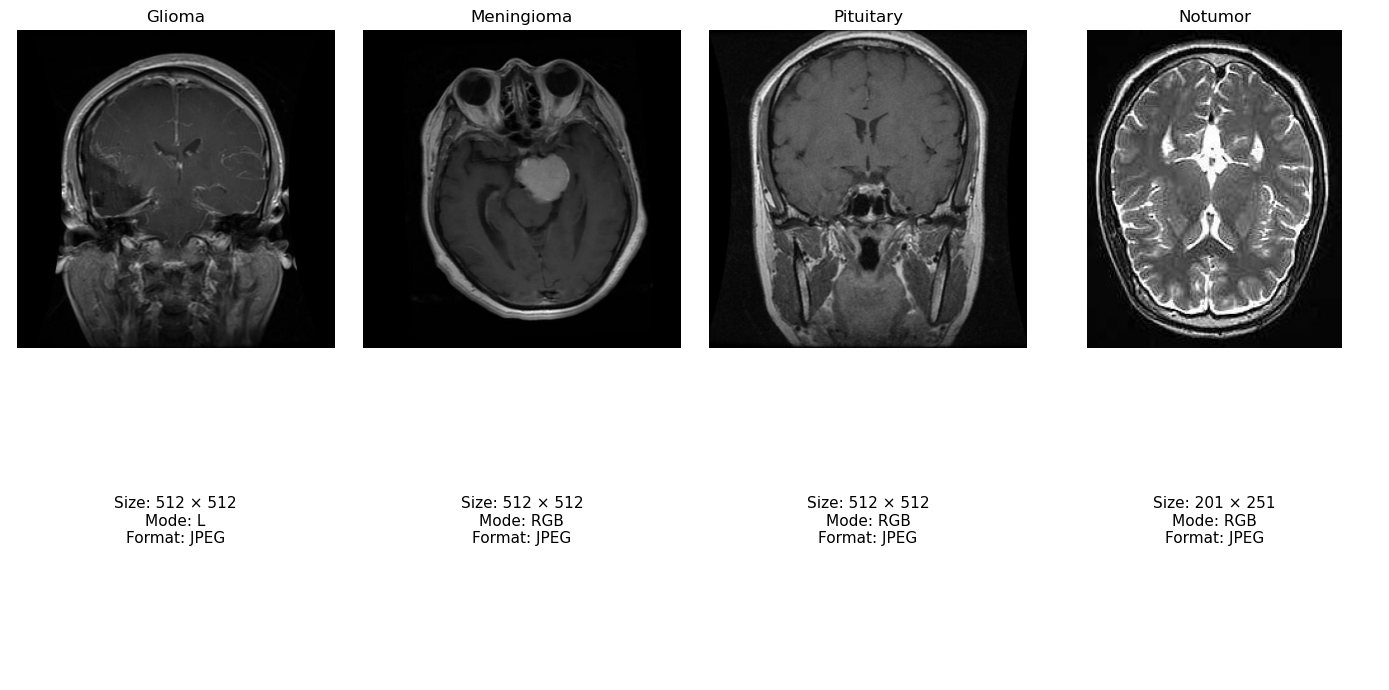

In [20]:
fig, axes = plt.subplots(2, 4, figsize=(14, 7))

for col, class_name in enumerate(classes):
    class_files = [
        file for file in (train_dir / class_name).iterdir()
        if file.suffix.lower() in image_extensions
    ]
    
    image = Image.open(class_files[0])
    
    axes[0, col].imshow(image, cmap="gray")
    axes[0, col].set_title(class_name)
    axes[0, col].axis("off")
    
    image_info_row = image_info[image_info["File"] == class_files[0].name].iloc[0]
    
    axes[1, col].text(
        0.5,
        0.5,
        f"Size: {image_info_row['Width']} × {image_info_row['Height']}\n"
        f"Mode: {image_info_row['Mode']}\n"
        f"Format: {image_info_row['Format']}",
        ha="center",
        va="center",
        fontsize=11
    )
    axes[1, col].axis("off")

plt.tight_layout()
plt.show()

#### Visual Comparison of Image Modes

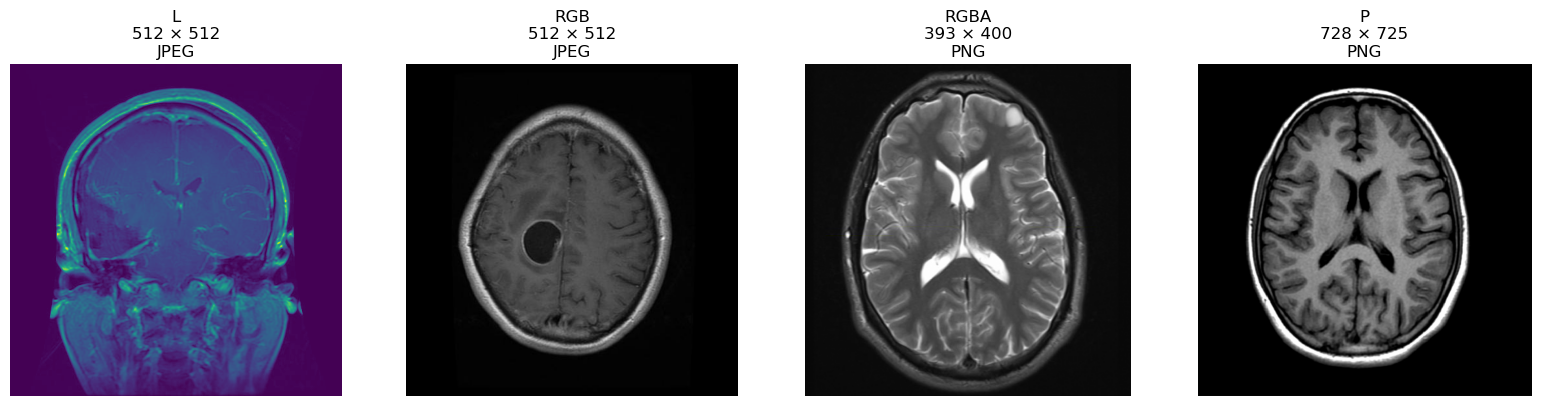

In [21]:
mode_examples = {}

for mode in ["L", "RGB", "RGBA", "P"]:
    mode_files = image_info[image_info["Mode"] == mode]
    
    if len(mode_files) > 0:
        row = mode_files.iloc[0]
        mode_examples[mode] = row

fig, axes = plt.subplots(1, len(mode_examples), figsize=(16, 4))

for ax, (mode, row) in zip(axes, mode_examples.items()):
    image_path = train_dir / row["Class"] / row["File"]
    image = Image.open(image_path)
    
    ax.imshow(image)
    ax.set_title(
        f"{mode}\n"
        f"{row['Width']} × {row['Height']}\n"
        f"{row['Format']}"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

#### Aspect Ratio Analysis

In [22]:
image_info["Aspect_Ratio"] = (
    image_info["Width"] / image_info["Height"]
)

print("Aspect ratio statistics:")
print(image_info["Aspect_Ratio"].describe())

Aspect ratio statistics:
count    5600.000000
mean        0.988435
std         0.079300
min         0.644809
25%         1.000000
50%         1.000000
75%         1.000000
max         1.785714
Name: Aspect_Ratio, dtype: float64


In [23]:
print("\nImages with the smallest aspect ratios:")

print(
    image_info.sort_values("Aspect_Ratio")[
        ["Class", "File", "Width", "Height", "Aspect_Ratio"]
    ].head(10)
)


Images with the smallest aspect ratios:
        Class            File  Width  Height  Aspect_Ratio
4280  Notumor  Tr-no_1070.jpg    236     366      0.644809
4949  Notumor   Tr-no_412.jpg    236     366      0.644809
4833  Notumor   Tr-no_308.jpg    236     357      0.661064
4399  Notumor  Tr-no_1178.jpg    236     357      0.661064
5039  Notumor   Tr-no_494.jpg    236     357      0.661064
4496  Notumor  Tr-no_1265.jpg    236     357      0.661064
4335  Notumor   Tr-no_112.jpg    236     357      0.661064
4598  Notumor  Tr-no_1357.jpg    216     302      0.715232
4813  Notumor   Tr-no_290.jpg    380     530      0.716981
5237  Notumor   Tr-no_672.jpg    380     530      0.716981


In [24]:
print("\nImages with the largest aspect ratios:")

print(
    image_info.sort_values("Aspect_Ratio", ascending=False)[
        ["Class", "File", "Width", "Height", "Aspect_Ratio"]
    ].head(10)
)


Images with the largest aspect ratios:
        Class            File  Width  Height  Aspect_Ratio
4655  Notumor   Tr-no_148.jpg    300     168      1.785714
4931  Notumor   Tr-no_397.jpg    300     168      1.785714
5181  Notumor   Tr-no_621.jpg    300     168      1.785714
4955  Notumor   Tr-no_418.jpg    300     168      1.785714
5418  Notumor   Tr-no_835.jpg    300     168      1.785714
5099  Notumor   Tr-no_548.jpg    300     168      1.785714
4511  Notumor  Tr-no_1279.jpg    300     168      1.785714
5024  Notumor   Tr-no_480.jpg    300     168      1.785714
4221  Notumor  Tr-no_1017.jpg    642     361      1.778393
4530  Notumor  Tr-no_1296.jpg    642     361      1.778393


## Image Integrity Check

In [25]:
def check_images(folder, classes):
    results = []
    
    for class_name in classes:
        class_dir = folder / class_name
        
        for file in class_dir.iterdir():
            if file.suffix.lower() in image_extensions:
                try:
                    with Image.open(file) as img:
                        img.verify()
                    
                    results.append({
                        "Class": class_name,
                        "File": file.name,
                        "Valid": True
                    })
                    
                except Exception as e:
                    results.append({
                        "Class": class_name,
                        "File": file.name,
                        "Valid": False
                    })
    
    return pd.DataFrame(results)

In [26]:
train_integrity = check_images(train_dir, classes)

print("Training images checked:", len(train_integrity))
print("Valid images:", train_integrity["Valid"].sum())
print("Invalid images:", (~train_integrity["Valid"]).sum())

Training images checked: 5600
Valid images: 5600
Invalid images: 0


In [27]:
test_integrity = check_images(test_dir, classes)

print("Testing images checked:", len(test_integrity))
print("Valid images:", test_integrity["Valid"].sum())
print("Invalid images:", (~test_integrity["Valid"]).sum())

Testing images checked: 1600
Valid images: 1600
Invalid images: 0


# PHASE 2. Train, Validation, and Test Split

#### Creating the Training Dataframe

In [28]:
training_data = []

for class_name in classes:
    class_dir = train_dir / class_name
    
    for file in class_dir.iterdir():
        if file.suffix.lower() in image_extensions:
            training_data.append({
                "File": file,
                "Class": class_name
            })

training_data = pd.DataFrame(training_data)

print("Total training images:", len(training_data))
training_data.head()

Total training images: 5600


,File,Class
0,C:\Users\BLOB\Desktop\AdvancedCompVision\Brain...,Glioma
1,C:\Users\BLOB\Desktop\AdvancedCompVision\Brain...,Glioma
2,C:\Users\BLOB\Desktop\AdvancedCompVision\Brain...,Glioma
3,C:\Users\BLOB\Desktop\AdvancedCompVision\Brain...,Glioma
4,C:\Users\BLOB\Desktop\AdvancedCompVision\Brain...,Glioma


#### Check the class distribution

In [29]:
print("Training class distribution:")
print(training_data["Class"].value_counts())

Training class distribution:
Class
Glioma        1400
Meningioma    1400
Pituitary     1400
Notumor       1400
Name: count, dtype: int64


#### Performing the stratified split

In [30]:
train_data, val_data = train_test_split(
    training_data,
    test_size=0.20,
    random_state=42,
    stratify=training_data["Class"]
)

In [31]:
print("Training images:", len(train_data))
print("Validation images:", len(val_data))

Training images: 4480
Validation images: 1120


In [32]:
print("Total:", len(train_data) + len(val_data))

Total: 5600


#### Verify stratification

In [33]:
print("Training class distribution:")
print(train_data["Class"].value_counts())

print("\nValidation class distribution:")
print(val_data["Class"].value_counts())

Training class distribution:
Class
Pituitary     1120
Notumor       1120
Glioma        1120
Meningioma    1120
Name: count, dtype: int64

Validation class distribution:
Class
Glioma        280
Meningioma    280
Pituitary     280
Notumor       280
Name: count, dtype: int64


#### Final split table

In [34]:
split_summary = pd.DataFrame({
    "Class": classes,
    "Training": [
        (train_data["Class"] == class_name).sum()
        for class_name in classes
    ],
    "Validation": [
        (val_data["Class"] == class_name).sum()
        for class_name in classes
    ],
    "Testing": [
        (test_dir / class_name).exists() and len([
            file for file in (test_dir / class_name).iterdir()
            if file.suffix.lower() in image_extensions
        ])
        for class_name in classes
    ]
})

split_summary

,Class,Training,Validation,Testing
0,Glioma,1120,280,400
1,Meningioma,1120,280,400
2,Pituitary,1120,280,400
3,Notumor,1120,280,400


#### Overall totals

In [35]:
print("Training:", split_summary["Training"].sum())
print("Validation:", split_summary["Validation"].sum())
print("Testing:", split_summary["Testing"].sum())
print("Total:", split_summary[["Training", "Validation", "Testing"]].sum().sum())

Training: 4480
Validation: 1120
Testing: 1600
Total: 7200


# PHASE 3. Preprocessing

### 3.1 Comparing Image Resizing Methods

In [36]:
non_square_images = image_info[
    (image_info["Width"] != image_info["Height"])
].copy()

non_square_images = non_square_images.sort_values(
    "Aspect_Ratio"
)

non_square_images[
    ["Class", "File", "Width", "Height", "Aspect_Ratio"]
].head(5)

,Class,File,Width,Height,Aspect_Ratio
4280,Notumor,Tr-no_1070.jpg,236,366,0.644809
4949,Notumor,Tr-no_412.jpg,236,366,0.644809
4399,Notumor,Tr-no_1178.jpg,236,357,0.661064
4833,Notumor,Tr-no_308.jpg,236,357,0.661064
4496,Notumor,Tr-no_1265.jpg,236,357,0.661064


#### other extremes

In [37]:
non_square_images.sort_values(
    "Aspect_Ratio",
    ascending=False
)[
    ["Class", "File", "Width", "Height", "Aspect_Ratio"]
].head(5)

,Class,File,Width,Height,Aspect_Ratio
4511,Notumor,Tr-no_1279.jpg,300,168,1.785714
4955,Notumor,Tr-no_418.jpg,300,168,1.785714
5181,Notumor,Tr-no_621.jpg,300,168,1.785714
4655,Notumor,Tr-no_148.jpg,300,168,1.785714
5418,Notumor,Tr-no_835.jpg,300,168,1.785714


#### Preserve aspect ratio + padding

In [38]:
def resize_direct(image, size=(224, 224)):
    return image.resize(size)

In [39]:
def resize_with_padding(image, size=(224, 224)):
    image = image.copy()
    image.thumbnail(size)

    new_image = Image.new("RGB", size, "black")

    left = (size[0] - image.width) // 2
    top = (size[1] - image.height) // 2

    new_image.paste(image, (left, top))

    return new_image

#### Two examples

In [40]:
tall_image_info = non_square_images.iloc[0]

wide_image_info = non_square_images.sort_values(
    "Aspect_Ratio",
    ascending=False
).iloc[0]

print("Tall image:")
print(tall_image_info[["Class", "File", "Width", "Height", "Aspect_Ratio"]])

print("\nWide image:")
print(wide_image_info[["Class", "File", "Width", "Height", "Aspect_Ratio"]])

Tall image:
Class                  Notumor
File            Tr-no_1070.jpg
Width                      236
Height                     366
Aspect_Ratio          0.644809
Name: 4280, dtype: object

Wide image:
Class                  Notumor
File            Tr-no_1279.jpg
Width                      300
Height                     168
Aspect_Ratio          1.785714
Name: 4511, dtype: object


#### loading the images

In [41]:
tall_path = (
    train_dir
    / tall_image_info["Class"]
    / tall_image_info["File"]
)

wide_path = (
    train_dir
    / wide_image_info["Class"]
    / wide_image_info["File"]
)

tall_image = Image.open(tall_path).convert("RGB")
wide_image = Image.open(wide_path).convert("RGB")

#### Comparing the two approaches 

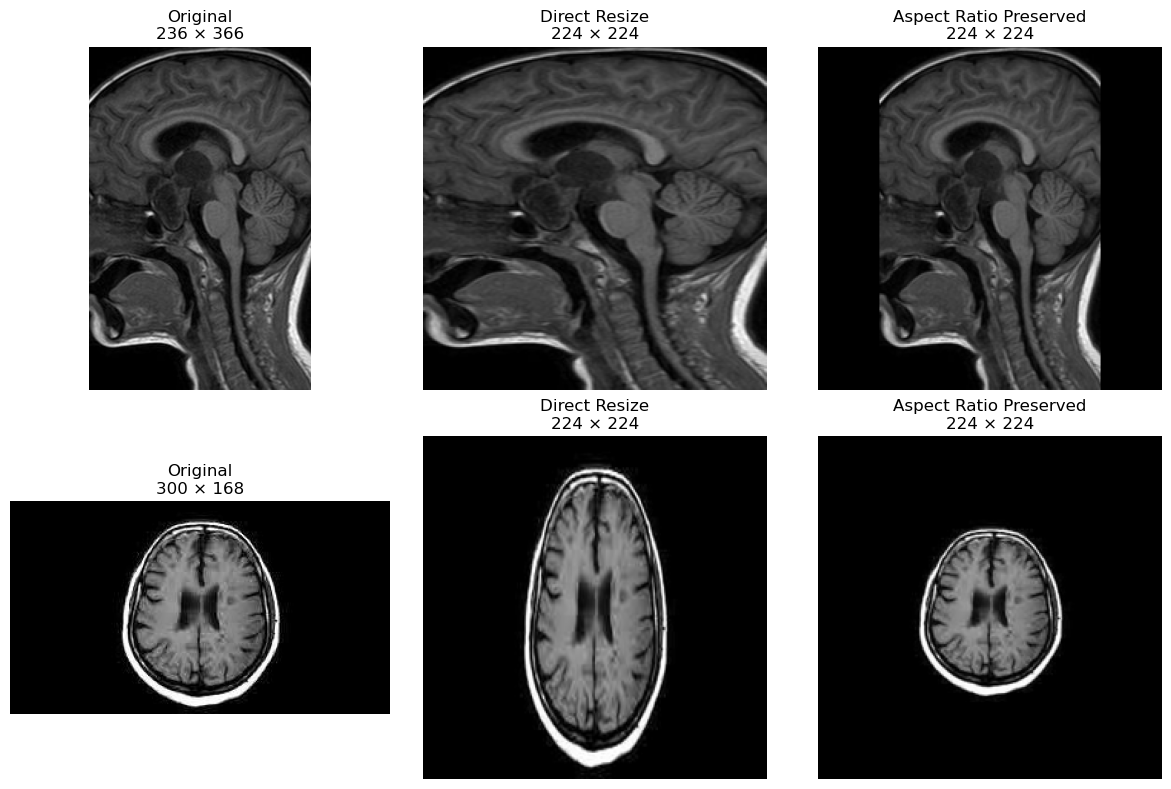

In [42]:
fig, axes = plt.subplots(2, 3, figsize=(12, 8))

# Tall image
axes[0, 0].imshow(tall_image)
axes[0, 0].set_title(
    f"Original\n{tall_image.width} × {tall_image.height}"
)
axes[0, 0].axis("off")

axes[0, 1].imshow(resize_direct(tall_image))
axes[0, 1].set_title("Direct Resize\n224 × 224")
axes[0, 1].axis("off")

axes[0, 2].imshow(resize_with_padding(tall_image))
axes[0, 2].set_title("Aspect Ratio Preserved\n224 × 224")
axes[0, 2].axis("off")


# Wide image
axes[1, 0].imshow(wide_image)
axes[1, 0].set_title(
    f"Original\n{wide_image.width} × {wide_image.height}"
)
axes[1, 0].axis("off")

axes[1, 1].imshow(resize_direct(wide_image))
axes[1, 1].set_title("Direct Resize\n224 × 224")
axes[1, 1].axis("off")

axes[1, 2].imshow(resize_with_padding(wide_image))
axes[1, 2].set_title("Aspect Ratio Preserved\n224 × 224")
axes[1, 2].axis("off")

plt.tight_layout()
plt.show()

The dataset audit identified substantial variation in image dimensions and aspect ratios. A visual comparison was conducted between direct resizing to 224 × 224 and aspect-ratio-preserving resizing with padding. The comparison showed visible geometric distortion in some non-square images when direct resizing was used. Therefore, both approaches will be considered in the preprocessing experiment and evaluated using the same model and validation set.

### 3.2 Pixel Intensity Analysis

In [43]:
def get_pixel_statistics(data):
    means = []
    stds = []

    for _, row in data.iterrows():
        with Image.open(row["File"]) as image:
            image = image.convert("RGB")
            pixels = np.asarray(image, dtype=np.float32) / 255.0

            means.append(pixels.mean(axis=(0, 1)))
            stds.append(pixels.std(axis=(0, 1)))

    return np.array(means), np.array(stds)

In [44]:
train_means, train_stds = get_pixel_statistics(train_data)

print("Mean RGB values:")
print(train_means.mean(axis=0))

print("\nStandard deviation of RGB values:")
print(train_stds.mean(axis=0))

Mean RGB values:
[0.18400963 0.18401249 0.18405645]

Standard deviation of RGB values:
[0.18391459 0.18391529 0.1839331 ]


Image-Level Pixel Intensity Summary An initial pixel-intensity analysis was performed by calculating the mean and standard deviation of each training image independently and then averaging those image-level statistics across the training subset. The resulting average RGB mean values were: [0.18400963, 0.18401249, 0.18405645] The resulting average RGB standard deviations were: [0.18391459, 0.18391529, 0.18393310] The three RGB channels show nearly identical values. This analysis provides an image-level description of the intensity characteristics across the training images.

#### Calculate the actual pixel statistics

In [45]:
def calculate_dataset_statistics(data):
    pixel_sum = np.zeros(3)
    pixel_squared_sum = np.zeros(3)
    pixel_count = 0

    for _, row in data.iterrows():
        with Image.open(row["File"]) as image:
            image = image.convert("RGB")
            pixels = np.asarray(image, dtype=np.float32) / 255.0

        pixels = pixels.reshape(-1, 3)

        pixel_sum += pixels.sum(axis=0)
        pixel_squared_sum += (pixels ** 2).sum(axis=0)
        pixel_count += pixels.shape[0]

    mean = pixel_sum / pixel_count
    variance = (pixel_squared_sum / pixel_count) - (mean ** 2)
    std = np.sqrt(variance)

    return mean, std

In [46]:
dataset_mean, dataset_std = calculate_dataset_statistics(train_data)

print("Dataset mean:")
print(dataset_mean)

print("\nDataset standard deviation:")
print(dataset_std)

Dataset mean:
[0.1736329  0.17363438 0.17364772]

Dataset standard deviation:
[0.18806462 0.18806351 0.18807067]


Dataset-Level Pixel Statistics A second pixel-intensity analysis was performed by pooling the pixel values across the 4,480 images in the training subset. Unlike the image-level analysis above, this calculation gives equal weight to each pixel rather than giving equal weight to each image. The resulting RGB channel means were approximately: [0.173633, 0.173634, 0.173648] The corresponding standard deviations were approximately: [0.188065, 0.188064, 0.188071] The three RGB channels again show nearly identical statistics. These values provide dataset-level intensity statistics and are therefore appropriate candidates for evaluating dataset-specific normalization. The statistics were calculated using the training subset only. The validation and held-out test images were not used to calculate these normalization parameters.

Interpretation of the Two Analyses The two analyses use different weighting approaches. The image-level analysis first calculates statistics separately for each image and then averages those statistics across images. The dataset-level analysis instead pools the pixels across the training dataset and calculates the overall pixel distribution. The image-level analysis is useful for describing the typical intensity characteristics of individual images. The dataset-level statistics are more appropriate for determining normalization parameters because normalization is applied to individual pixel values. Therefore, both analyses are retained as part of the dataset audit, while the dataset-level statistics will be used as the candidate parameters if dataset-specific normalization is evaluated.

## 3.3 Image Size and Aspect-Ratio Decision

In [47]:
square_images = image_info[
    image_info["Width"] == image_info["Height"]
]

non_square_images = image_info[
    image_info["Width"] != image_info["Height"]
]

print("Square images:", len(square_images))
print("Non-square images:", len(non_square_images))

print("\nPercentage square:",
      round(len(square_images) / len(image_info) * 100, 2), "%")

print("Percentage non-square:",
      round(len(non_square_images) / len(image_info) * 100, 2), "%")

Square images: 4510
Non-square images: 1090

Percentage square: 80.54 %
Percentage non-square: 19.46 %


#### Measure substantial aspect ratio differences

In [48]:
moderate_aspect_variation = image_info[
    (image_info["Aspect_Ratio"] < 0.90) |
    (image_info["Aspect_Ratio"] > 1.10)
]

print("Images outside 0.90–1.10 aspect ratio:",
      len(moderate_aspect_variation))

print(
    "Percentage:",
    round(
        len(moderate_aspect_variation) / len(image_info) * 100,
        2
    ),
    "%"
)

Images outside 0.90–1.10 aspect ratio: 593
Percentage: 10.59 %


We then measured the aspect-ratio variation across the dataset to identify images with noticeable differences in shape. While minor differences, such as 512 × 510, indicate images that are nearly square, larger differences, such as 300 × 168, represent more substantial variations in image geometry. Using **0.90–1.10 as a descriptive range around a square aspect ratio, we identified the images that fell outside this range and calculated both their total number and percentage of the dataset. This allowed us to quantify the extent of aspect-ratio variation before applying any preprocessing or resizing. The 0.90–1.10 range was used only as a descriptive threshold and is not intended to represent a medical or scientifically established standard.

#### Distribution by class

In [49]:
aspect_by_class = image_info.groupby("Class")["Aspect_Ratio"].agg(
    ["min", "median", "max"]
)

aspect_by_class

,min,median,max
Class,,,
Glioma,1.000000,1.0,1.000000
Meningioma,0.728155,1.0,1.590909
Notumor,0.644809,1.0,1.785714
Pituitary,0.798450,1.0,1.214575


In [50]:
variation_by_class = pd.crosstab(
    image_info["Class"],
    (
        (image_info["Aspect_Ratio"] < 0.90) |
        (image_info["Aspect_Ratio"] > 1.10)
    )
)

variation_by_class.columns = [
    "Within 0.90-1.10",
    "Outside 0.90-1.10"
]

variation_by_class

,Within 0.90-1.10,Outside 0.90-1.10
Class,,
Glioma,1400,0
Meningioma,1337,63
Notumor,878,522
Pituitary,1392,8


#### Quantify visual distortion mathematically

In [51]:
image_info["Width_Scale"] = 224 / image_info["Width"]
image_info["Height_Scale"] = 224 / image_info["Height"]

image_info["Scale_Difference"] = (
    abs(image_info["Width_Scale"] - image_info["Height_Scale"])
)

print(
    image_info[
        ["Class", "File", "Width", "Height",
         "Width_Scale", "Height_Scale", "Scale_Difference"]
    ]
    .sort_values("Scale_Difference", ascending=False)
    .head(10)
)

        Class            File  Width  Height  Width_Scale  Height_Scale  \
4511  Notumor  Tr-no_1279.jpg    300     168     0.746667      1.333333   
5099  Notumor   Tr-no_548.jpg    300     168     0.746667      1.333333   
4955  Notumor   Tr-no_418.jpg    300     168     0.746667      1.333333   
5181  Notumor   Tr-no_621.jpg    300     168     0.746667      1.333333   
4931  Notumor   Tr-no_397.jpg    300     168     0.746667      1.333333   
5024  Notumor   Tr-no_480.jpg    300     168     0.746667      1.333333   
5418  Notumor   Tr-no_835.jpg    300     168     0.746667      1.333333   
4655  Notumor   Tr-no_148.jpg    300     168     0.746667      1.333333   
4313  Notumor   Tr-no_110.jpg    275     183     0.814545      1.224044   
4360  Notumor  Tr-no_1142.jpg    275     183     0.814545      1.224044   

      Scale_Difference  
4511          0.586667  
5099          0.586667  
4955          0.586667  
5181          0.586667  
4931          0.586667  
5024          0.586667  

#### Resizing Strategy Decision

The training subset contains **5,600 images**, of which **4,510 (80.54%)** are square and **1,090 (19.46%)** are non-square. Using a descriptive aspect-ratio range of **0.90–1.10**, **593 images (10.59%)** fall outside this range.

Aspect-ratio variation is not distributed equally across the four classes. The **Notumor** class contains the largest number of images outside the 0.90–1.10 range, with **522 images**, followed by **Meningioma** with **63 images** and **Pituitary** with **8 images**. No **Glioma** images fall outside this descriptive range. This observation describes the composition of the dataset and is not interpreted as evidence that aspect ratio is inherently associated with tumor class.

The visual resizing comparison demonstrated that directly resizing substantially non-square images to **224 × 224** can alter their geometric proportions. The scale-factor analysis also showed substantial differences between horizontal and vertical scaling for some images. For example, images with dimensions of **300 × 168** require horizontal and vertical scale factors of approximately **0.747** and **1.333**, respectively, when directly resized to **224 × 224**.

Based on these observations, **aspect-ratio-preserving resizing followed by padding to 224 × 224** will be used as the primary preprocessing candidate. Direct resizing to **224 × 224** will be retained as a baseline for later comparison. The final choice will be evaluated quantitatively using the validation set under otherwise equivalent experimental conditions.

## 3.4 Implementing Aspect-Ratio-Preserving Resize

In [52]:
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

In [53]:
class ResizeWithPadding:
    def __init__(self, size=(224, 224)):
        self.size = size

    def __call__(self, image):
        image = image.copy()
        image.thumbnail(self.size)

        new_image = Image.new("RGB", self.size, "black")

        left = (self.size[0] - image.width) // 2
        top = (self.size[1] - image.height) // 2

        new_image.paste(image, (left, top))

        return new_image

In [54]:
resize_transform = transforms.Compose([
    transforms.Lambda(lambda image: image.convert("RGB")),
    ResizeWithPadding((224, 224))
])

In [55]:
test_tall = resize_transform(tall_image)
test_wide = resize_transform(wide_image)

print("Tall image:", test_tall.size, test_tall.mode)
print("Wide image:", test_wide.size, test_wide.mode)

Tall image: (224, 224) RGB
Wide image: (224, 224) RGB


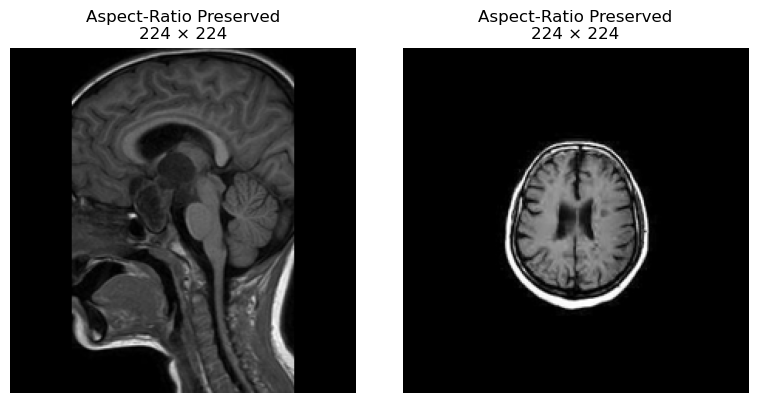

In [56]:
fig, axes = plt.subplots(1, 2, figsize=(8, 4))

axes[0].imshow(test_tall)
axes[0].set_title("Aspect-Ratio Preserved\n224 × 224")
axes[0].axis("off")

axes[1].imshow(test_wide)
axes[1].set_title("Aspect-Ratio Preserved\n224 × 224")
axes[1].axis("off")

plt.tight_layout()
plt.show()

Resize Implementation Verification

The aspect-ratio-preserving transformation was tested using representative non-square MRI images from the training dataset. Both images were successfully converted to RGB and transformed to a final size of **224 × 224 pixels**.

Visual inspection confirmed that the transformation preserved the original image proportions while using padding to achieve the required square input dimensions. No noticeable geometric stretching was observed in the tested examples.

## 3.5 Normalization Comparison

Normalization is required to scale the image pixel values before they are provided to the neural network. Two normalization strategies will be considered in this project.
The first uses the standard ImageNet statistics associated with the pretrained ResNet-18 weights. The second uses statistics calculated from the 4,480 training images in this dataset.

The ImageNet values will serve as the transfer-learning baseline, while the dataset-specific values will be evaluated as an alternative.

In [57]:
imagenet_mean = [0.485, 0.456, 0.406]
imagenet_std = [0.229, 0.224, 0.225]

dataset_mean = dataset_mean.tolist()
dataset_std = dataset_std.tolist()

print("ImageNet mean:", imagenet_mean)
print("ImageNet std:", imagenet_std)

print("\nDataset mean:", dataset_mean)
print("Dataset std:", dataset_std)

ImageNet mean: [0.485, 0.456, 0.406]
ImageNet std: [0.229, 0.224, 0.225]

Dataset mean: [0.17363289982528188, 0.1736343754372242, 0.1736477238537908]
Dataset std: [0.18806461776720196, 0.18806351106821353, 0.18807066792417737]


#### The two preprocessing pipelines

In [58]:
preprocess_imagenet = transforms.Compose([
    transforms.Lambda(lambda image: image.convert("RGB")),
    ResizeWithPadding((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(imagenet_mean, imagenet_std)
])

In [59]:
preprocess_dataset = transforms.Compose([
    transforms.Lambda(lambda image: image.convert("RGB")),
    ResizeWithPadding((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(dataset_mean, dataset_std)
])

#### Apply both to the same image

In [60]:
imagenet_tensor = preprocess_imagenet(tall_image)
dataset_tensor = preprocess_dataset(tall_image)

print("ImageNet-normalized tensor:")
print("Shape:", imagenet_tensor.shape)
print("Minimum:", imagenet_tensor.min().item())
print("Maximum:", imagenet_tensor.max().item())
print("Mean:", imagenet_tensor.mean().item())

print("\nDataset-normalized tensor:")
print("Shape:", dataset_tensor.shape)
print("Minimum:", dataset_tensor.min().item())
print("Maximum:", dataset_tensor.max().item())
print("Mean:", dataset_tensor.mean().item())

ImageNet-normalized tensor:
Shape: torch.Size([3, 224, 224])
Minimum: -2.1179039478302
Maximum: 2.552854299545288
Mean: -1.3573864698410034

Dataset-normalized tensor:
Shape: torch.Size([3, 224, 224])
Minimum: -0.9233109951019287
Maximum: 4.289815425872803
Mean: -0.16791880130767822


#### Visual Sanity Check

In [61]:
def denormalize(tensor, mean, std):
    mean = torch.tensor(mean).view(3, 1, 1)
    std = torch.tensor(std).view(3, 1, 1)

    image = tensor * std + mean
    image = image.clamp(0, 1)

    return image.permute(1, 2, 0).numpy()

In [62]:
imagenet_display = denormalize(
    imagenet_tensor,
    imagenet_mean,
    imagenet_std
)

dataset_display = denormalize(
    dataset_tensor,
    dataset_mean,
    dataset_std
)

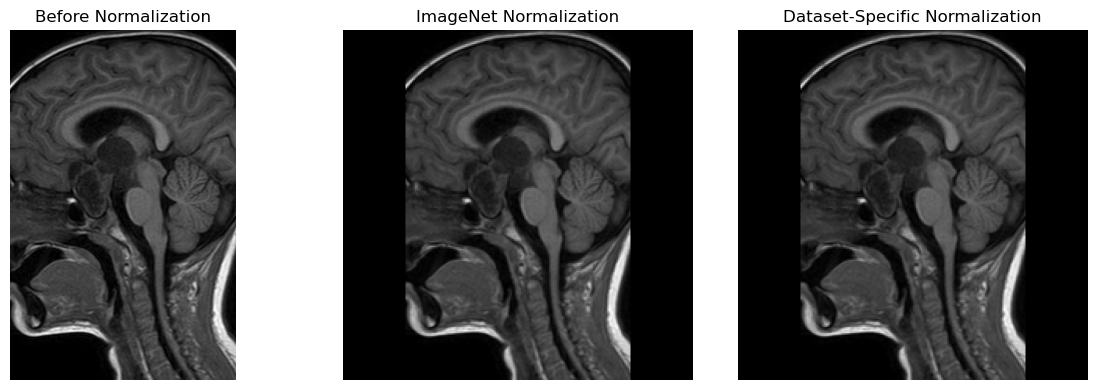

In [63]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

axes[0].imshow(tall_image)
axes[0].set_title("Before Normalization")
axes[0].axis("off")

axes[1].imshow(imagenet_display)
axes[1].set_title("ImageNet Normalization")
axes[1].axis("off")

axes[2].imshow(dataset_display)
axes[2].set_title("Dataset-Specific Normalization")
axes[2].axis("off")

plt.tight_layout()
plt.show()

Normalization Verification

The two normalization strategies were applied to the same aspect-ratio- preserved MRI image. After normalization, both tensors retained the expected shape of 3 × 224 × 224.

The normalized tensors were subsequently denormalized for visual inspection. The resulting images retained the same anatomical structure as the original image, indicating that normalization did not introduce visible geometric distortion or alter the underlying image structure.

The ImageNet normalization will therefore remain the transfer-learning baseline, while dataset-specific normalization will be retained as an alternative for the controlled model comparison.

#### Training Data Augmentation

Data augmentation will be applied only to the training subset. The purpose is to introduce controlled variation in the training images while preserving the visual characteristics relevant to four-class brain MRI
classification.

Two conservative geometric transformations will initially be evaluated: horizontal flipping and small-angle rotation. Validation and testing images will not receive random augmentation.

The augmentation strategy will be visually inspected before being included in the final preprocessing pipeline.

#### Create the augmentation

In [64]:
train_augmentation = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10)
])

#### Generating several versions of the same MRI

In [65]:
augmented_images = []

for _ in range(4):
    augmented_images.append(
        train_augmentation(tall_image)
    )

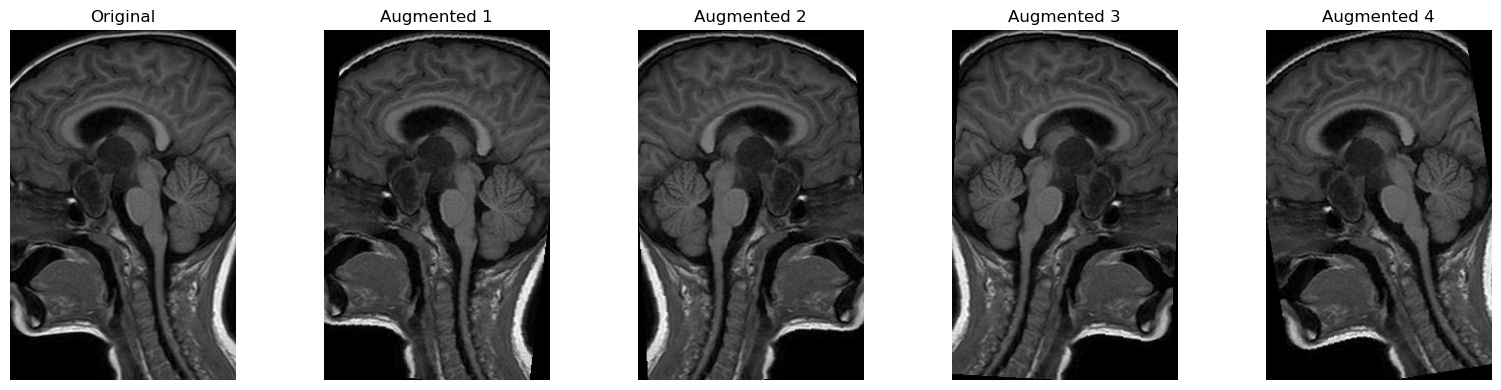

In [66]:
fig, axes = plt.subplots(1, 5, figsize=(16, 4))

axes[0].imshow(tall_image)
axes[0].set_title("Original")
axes[0].axis("off")

for i, image in enumerate(augmented_images):
    axes[i + 1].imshow(image)
    axes[i + 1].set_title(f"Augmented {i + 1}")
    axes[i + 1].axis("off")

plt.tight_layout()
plt.show()

### Training Preprocessing Pipeline Verification

The augmentation strategy was visually inspected using repeated transformations of the same MRI image. The augmented examples preserved the recognizable anatomical structure while introducing left-right and small orientation variations.

The complete training preprocessing pipeline will now be tested to verify that resizing, padding, augmentation, tensor conversion, and normalization work together as intended.

In [67]:
train_transform = transforms.Compose([
    transforms.Lambda(lambda image: image.convert("RGB")),
    ResizeWithPadding((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ToTensor(),
    transforms.Normalize(imagenet_mean, imagenet_std)
])

In [68]:
evaluation_transform = transforms.Compose([
    transforms.Lambda(lambda image: image.convert("RGB")),
    ResizeWithPadding((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(imagenet_mean, imagenet_std)
])

In [69]:
augmented_tensors = []

for _ in range(4):
    augmented_tensors.append(
        train_transform(tall_image)
    )

In [70]:
def display_tensor_image(tensor, mean, std):
    image = tensor.clone()

    mean = torch.tensor(mean).view(3, 1, 1)
    std = torch.tensor(std).view(3, 1, 1)

    image = image * std + mean
    image = image.clamp(0, 1)

    return image.permute(1, 2, 0).numpy()

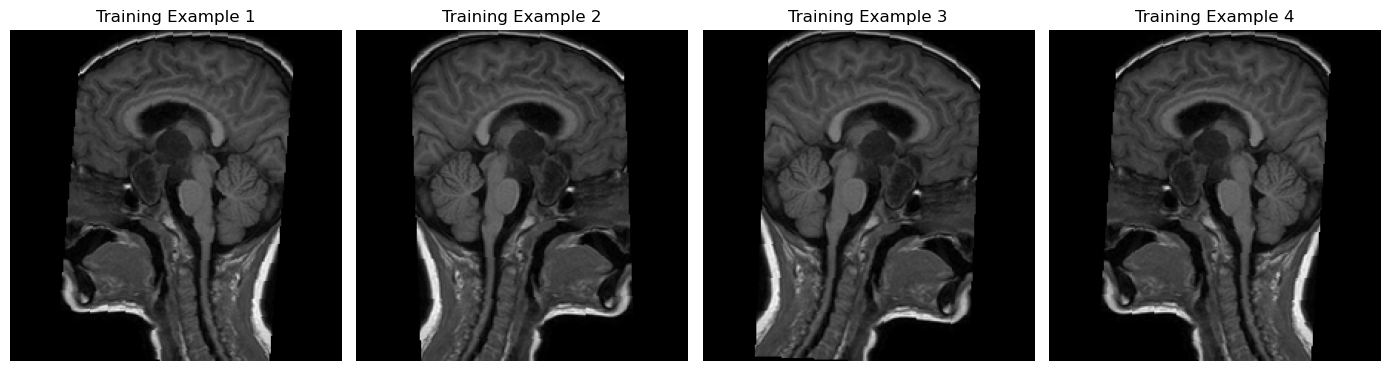

In [71]:
fig, axes = plt.subplots(1, 4, figsize=(14, 4))

for i, tensor in enumerate(augmented_tensors):
    image = display_tensor_image(
        tensor,
        imagenet_mean,
        imagenet_std
    )

    axes[i].imshow(image)
    axes[i].set_title(f"Training Example {i + 1}")
    axes[i].axis("off")

plt.tight_layout()
plt.show()

#### Augmentation Verification

The complete training preprocessing pipeline was tested using representative MRI images. The pipeline converts images to RGB, preserves the original aspect ratio while resizing to 224 × 224 pixels, applies random horizontal
flipping and small-angle rotation, converts the result to a tensor, and applies ImageNet normalization.

Visual inspection of repeated transformations showed that the augmented images retained recognizable anatomical structure while introducing  moderate geometric variation. No obvious excessive cropping or severe distortion was observed in the tested examples.

Random augmentation will therefore be restricted to the training subset. Validation and testing images will use the deterministic evaluation pipeline without random augmentation.

# POST MIDTERM

## Model Selection and Alternative Comparison

# Model Selection and Alternative Comparison

## 3.7 Model Selection and Alternative Comparison

Model selection was treated as a structured comparison rather than selecting a CNN based only on popularity or familiarity. The objective was to identify an architecture that is appropriate for the four-class MRI classification problem while also considering dataset size, computational requirements, transfer-learning availability, and the overall scope of the project.

Five candidate CNN architectures were selected for comparison:

1. **MobileNetV3-Small**
2. **EfficientNet-B0**
3. **ResNet-18**
4. **ResNet-34**
5. **ResNet-50**

After midterm feedback, the comparison was expanded from three to five candidates so that the residual family is covered properly. The project still implements and evaluates **one final CNN architecture**, and the other four architectures are used to provide evidence for the selection.

The winner is decided only after all five candidates have been compared on accuracy, macro precision, macro recall and macro F1, together with per-class results and confusion matrices. Accuracy alone is not used to declare a winner. All comparisons use the validation set only, and the held-out test set is not used.

### 3.7.1 Why These Five Architectures?

The five architectures were selected because they cover a range of sizes (about 2.5 million to 25 million parameters) and two design families: efficient scaled networks and residual networks. All five have pretrained ImageNet weights in torchvision, so the same transfer-learning protocol can be applied to every one.

**MobileNetV3-Small** was selected as the lightweight reference model. It shows whether a very small CNN has enough capacity for the four-class MRI task.

**EfficientNet-B0** was selected as an intermediate efficient architecture with more capacity than MobileNetV3-Small, while still being much smaller than the ResNets.

**ResNet-18** was selected because it is the architecture specified in the original project proposal. It is the smallest ResNet.

**ResNet-34** and **ResNet-50** were added after the midterm feedback, which pointed out that ResNet-18 is the weakest ResNet. They test whether deeper residual networks perform better on this dataset.

Larger or different families such as VGG, DenseNet and Vision Transformers were left out because they are much heavier than this project's computational limits allow, and because the project is scoped to one final CNN architecture.

The final architecture is chosen from this comparison. It was not fixed in advance.

### 3.7.2 Candidate Architecture Comparison

The candidate architectures were compared using four main considerations:

- **Model complexity:** the number of parameters gives an objective indication of model size.
- **Computational requirements:** GFLOPs give a basis for comparing the approximate cost of processing a 224×224 image.
- **Transfer-learning availability:** pretrained ImageNet weights let the models adapt to the MRI task without training from scratch.
- **Measured performance:** accuracy, macro precision, macro recall and macro F1 on the validation set, with per-class results.

The comparison supports the final architecture selection with measurable evidence rather than a general statement that one architecture is popular.

In [72]:
import torch
import pandas as pd
import torchvision.models as models

print("PyTorch version:", torch.__version__)
print("Model-selection libraries loaded successfully.")

PyTorch version: 2.8.0+cpu
Model-selection libraries loaded successfully.


### Instantiating the Candidate Architectures

The five candidate architectures are instantiated using torchvision without pretrained weights at this stage. This allows their parameter counts to be compared without loading large pretrained files.

Pretrained ImageNet weights are loaded later, for the feature-extraction comparison.

The five candidates are:

- **MobileNetV3-Small:** lightweight and computationally efficient.
- **EfficientNet-B0:** efficient architecture with more capacity than MobileNetV3-Small.
- **ResNet-18:** smallest residual architecture, inherited from the original proposal.
- **ResNet-34:** medium residual architecture, added after midterm feedback.
- **ResNet-50:** deeper residual architecture, added after midterm feedback.

#### make the five architectures, no pretrained weights yet

In [73]:
# make the five architectures, no pretrained weights yet
mobilenet_v3_small = models.mobilenet_v3_small(weights=None)
efficientnet_b0 = models.efficientnet_b0(weights=None)
resnet18 = models.resnet18(weights=None)
resnet34 = models.resnet34(weights=None)
resnet50 = models.resnet50(weights=None)

architectures = {
    "MobileNetV3-Small": mobilenet_v3_small,
    "EfficientNet-B0": efficientnet_b0,
    "ResNet-18": resnet18,
    "ResNet-34": resnet34,
    "ResNet-50": resnet50
}

for name in architectures:
    print(name, "instantiated successfully.")

MobileNetV3-Small instantiated successfully.
EfficientNet-B0 instantiated successfully.
ResNet-18 instantiated successfully.
ResNet-34 instantiated successfully.
ResNet-50 instantiated successfully.


#### Model Parameter Comparison

The number of parameters is an objective measure of the size and complexity of each candidate. Models with more parameters generally have more representational capacity, but they also need more memory and computation.

Parameter count does not by itself decide classification performance. It is one measurable factor for judging whether each candidate's complexity suits the dataset and the project's computational limits.

In [74]:
def count_parameters(model):
    total = 0
    for parameter in model.parameters():
        total = total + parameter.numel()
    return total

for name in architectures:
    print(name, "parameters:", format(count_parameters(architectures[name]), ","))

MobileNetV3-Small parameters: 2,542,856
EfficientNet-B0 parameters: 5,288,548
ResNet-18 parameters: 11,689,512
ResNet-34 parameters: 21,797,672
ResNet-50 parameters: 25,557,032


#### Parameter Count Comparison

The parameter counts show a clear difference in model size among the five candidates.

MobileNetV3-Small has about 2.54 million parameters and is the smallest. EfficientNet-B0 has about 5.29 million. ResNet-18 has about 11.69 million, ResNet-34 about 21.80 million, and ResNet-50 about 25.56 million, which is the largest.

This gives five different levels of model capacity, from lightweight to large, and shows that the choice of ResNet-18 in the original proposal was one point on a wider range and not the only reasonable option.

In [75]:
comparison_rows = []

for name in architectures:
    params = count_parameters(architectures[name])
    comparison_rows.append({
        "Model": name,
        "Parameters": params,
        "Parameters (Millions)": round(params / 1000000, 2)
    })

model_comparison = pd.DataFrame(comparison_rows)
model_comparison

,Model,Parameters,Parameters (Millions)
0,MobileNetV3-Small,2542856,2.54
1,EfficientNet-B0,5288548,5.29
2,ResNet-18,11689512,11.69
3,ResNet-34,21797672,21.80
4,ResNet-50,25557032,25.56


### Computational Complexity Comparison

Parameter count measures model size, but it does not fully describe computational cost. The candidates are therefore also compared by the approximate GFLOPs (billions of floating-point operations) needed for one 224×224 image. Lower GFLOPs means a cheaper forward pass.

This matters here because the selected model is used for training, clean-image testing, and testing on noisy and blurred images, so the cost of each model is paid several times.

In [76]:
# approximate GFLOPs for a 224x224 image, from the torchvision documentation
gflops = {
    "MobileNetV3-Small": 0.06,
    "EfficientNet-B0": 0.39,
    "ResNet-18": 1.81,
    "ResNet-34": 3.66,
    "ResNet-50": 4.09
}

gflops_list = []
for name in model_comparison["Model"]:
    gflops_list.append(gflops[name])

model_comparison["GFLOPs @ 224x224"] = gflops_list
model_comparison

,Model,Parameters,Parameters (Millions),GFLOPs @ 224x224
0,MobileNetV3-Small,2542856,2.54,0.06
1,EfficientNet-B0,5288548,5.29,0.39
2,ResNet-18,11689512,11.69,1.81
3,ResNet-34,21797672,21.80,3.66
4,ResNet-50,25557032,25.56,4.09


### Visualization of Model Parameter Counts

The chart shows how the five candidates differ in size. ResNet-50 has roughly ten times as many parameters as MobileNetV3-Small, so the five models cover a wide range of capacity.

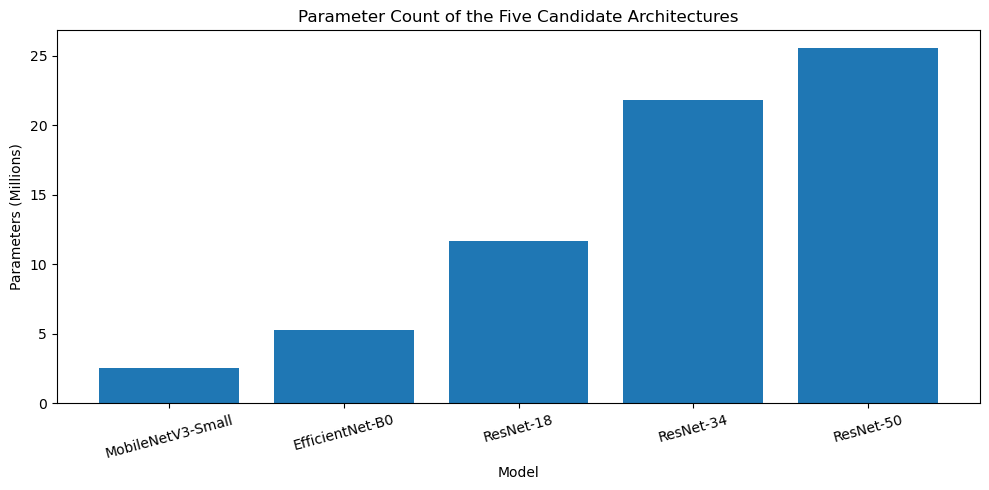

In [77]:
plt.figure(figsize=(10, 5))
plt.bar(model_comparison["Model"], model_comparison["Parameters (Millions)"])
plt.xlabel("Model")
plt.ylabel("Parameters (Millions)")
plt.title("Parameter Count of the Five Candidate Architectures")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

#### Visualization of Computational Complexity

The computational cost grows faster than the parameter count. ResNet-50 needs about 4.09 GFLOPs per image, while MobileNetV3-Small needs about 0.06. A larger cost is only worth paying if the larger model performs clearly better, which is tested in the next sections.

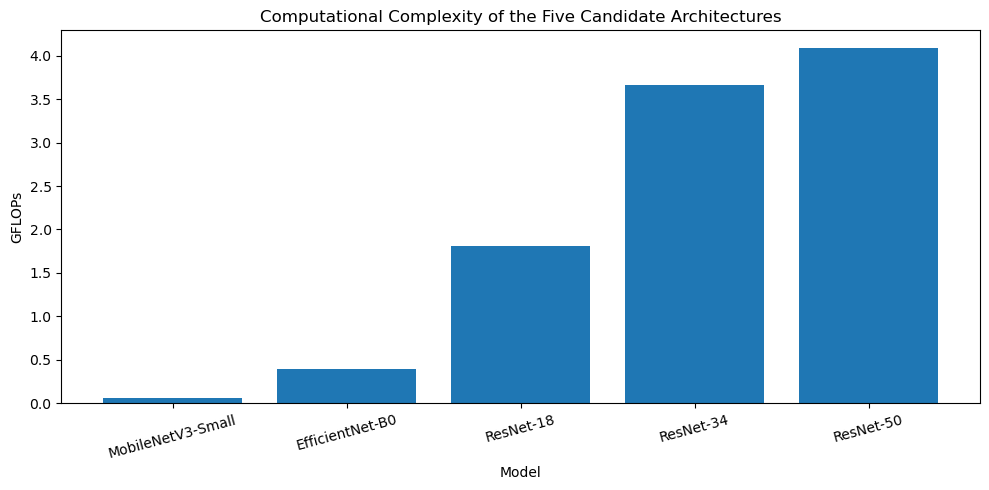

In [78]:
plt.figure(figsize=(10, 5))
plt.bar(model_comparison["Model"], model_comparison["GFLOPs @ 224x224"])
plt.xlabel("Model")
plt.ylabel("GFLOPs")
plt.title("Computational Complexity of the Five Candidate Architectures")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

## Dataset Size vs. Model Complexity

The dataset contains 7,200 MRI images: 5,600 in the original training partition and 1,600 in the original testing partition. After the stratified 80/20 split, 4,480 images are used for training and 1,120 for validation. The 1,600-image test set stays untouched until final evaluation.

A larger parameter count does not automatically give better classification performance. More capacity can add representational power, but it also costs more to run and can be harder to train with a limited amount of task-specific data. The goal is a model with enough capacity for the four-class problem at a reasonable cost, so the five candidates are compared by measured performance and not by size alone.

### Fit to the Project's Computational Constraints

The chosen model is used throughout the whole pipeline: training on 4,480 images, validation on 1,120, testing on 1,600 clean images, and then the same test images with Gaussian noise and Gaussian blur at several levels. A very expensive model multiplies the cost of every one of these stages, so the cost of each candidate is part of the decision as well as its accuracy.

### Transfer-Learning Suitability

All five candidates have pretrained ImageNet weights available in torchvision. Their original 1,000-class output layer is replaced with a four-class layer for Glioma, Meningioma, Pituitary tumor and No tumor.

## Adaptation to the Four Target Classes

Each pretrained model ends in a layer with 1,000 outputs for the ImageNet classes. This final layer is removed or replaced so that the model can be used for the four MRI classes. The cell below shows the last layer of each candidate.

In [79]:
# look at the last layer of each model (it has 1000 outputs for ImageNet)
print("MobileNetV3-Small classifier:")
print(mobilenet_v3_small.classifier)
print()
print("EfficientNet-B0 classifier:")
print(efficientnet_b0.classifier)
print()
print("ResNet-18 fc:", resnet18.fc)
print("ResNet-34 fc:", resnet34.fc)
print("ResNet-50 fc:", resnet50.fc)

MobileNetV3-Small classifier:
Sequential(
  (0): Linear(in_features=576, out_features=1024, bias=True)
  (1): Hardswish()
  (2): Dropout(p=0.2, inplace=True)
  (3): Linear(in_features=1024, out_features=1000, bias=True)
)

EfficientNet-B0 classifier:
Sequential(
  (0): Dropout(p=0.2, inplace=True)
  (1): Linear(in_features=1280, out_features=1000, bias=True)
)

ResNet-18 fc: Linear(in_features=512, out_features=1000, bias=True)
ResNet-34 fc: Linear(in_features=512, out_features=1000, bias=True)
ResNet-50 fc: Linear(in_features=2048, out_features=1000, bias=True)


## 3.9 Quantitative Evidence for Model and Resize Selection

The five candidates are now compared with actual results. Two questions are answered at the same time:

1. Which of the five architectures performs best?
2. Which resizing method should be used, given the shortcut check that showed padding keeps the aspect-ratio signal?

For every candidate, the pretrained ImageNet feature layers are frozen and the original ImageNet classification layer is removed. The resulting features are used to train the same logistic regression classifier. Each of the five models is tested with each of the three resize options (black padding, direct resize and center crop), giving 15 combinations in total. Because the classification procedure is identical, differences in performance come from the architecture and the resize option.

All results are on the validation set. The held-out test set is not used.

### Decision Rule (Set Before Looking at the Results)

1. **Model:** the winner is chosen using accuracy, macro precision, macro recall and macro F1 together, not accuracy alone. The model with the best average rank across the four metrics, and the best macro F1, is preferred. If the top models are not statistically different, the smaller model is chosen.
2. **Resize:** if a resize option without black bars performs about as well as black padding, the option without bars is used, because it removes the aspect-ratio shortcut. If every option without bars is clearly worse, padding is kept and the shortcut is reported as a limitation.

## Resize Options

Three ways of making every image 224 x 224 are compared in the model comparison:

1. **Black padding:** keeps the original proportions and fills the rest of the square with black bars.
2. **Direct resize:** stretches the image to 224 x 224 with no bars.
3. **Center crop:** cuts the longer side down to a square from the middle, then resizes. There are no bars and no stretching, but the edges of non-square images are removed.

The center crop is defined here as a small class. The padding resize already exists from the earlier preprocessing section.

In [82]:
# center crop: cut the longer side down to a square, then resize to 224 x 224
class CenterCropSquare:
    def __init__(self, size=224):
        self.size = size

    def __call__(self, image):
        w, h = image.size
        side = min(w, h)
        left = (w - side) // 2
        top = (h - side) // 2
        image = image.crop((left, top, left + side, top + side))
        image = image.resize((self.size, self.size))
        return image

resize_options = {
    "padding_black": ResizeWithPadding((224, 224)),
    "direct_resize": transforms.Resize((224, 224)),
    "center_crop": CenterCropSquare(224)
}

print("Options:", list(resize_options.keys()))

Options: ['padding_black', 'direct_resize', 'center_crop']


In [83]:
# load the pretrained version of each model and freeze it
pretrained_models = {
    "MobileNetV3-Small": models.mobilenet_v3_small(weights=models.MobileNet_V3_Small_Weights.DEFAULT),
    "EfficientNet-B0": models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.DEFAULT),
    "ResNet-18": models.resnet18(weights=models.ResNet18_Weights.DEFAULT),
    "ResNet-34": models.resnet34(weights=models.ResNet34_Weights.DEFAULT),
    "ResNet-50": models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
}

extractors = {}

for name in pretrained_models:
    model = pretrained_models[name].to(device)

    # freeze everything
    for parameter in model.parameters():
        parameter.requires_grad = False

    # take off the final ImageNet layer so the model gives us features
    if name == "MobileNetV3-Small" or name == "EfficientNet-B0":
        model.classifier = nn.Identity()
    else:
        model.fc = nn.Identity()

    model.eval()
    extractors[name] = model

model_names = list(extractors.keys())
option_names = list(resize_options.keys())

print("Feature extractors ready:", model_names)

Feature extractors ready: ['MobileNetV3-Small', 'EfficientNet-B0', 'ResNet-18', 'ResNet-34', 'ResNet-50']


### Feature Extraction Functions

Two helper functions are used. The first passes images through a frozen model and collects the features and labels. The second saves the features to disk after the first run, so the slow extraction does not have to be repeated if the notebook is restarted.

In [88]:
def extract_features(model, loader, device):
    model.eval()

    all_features = []
    all_labels = []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            features = model(images)
            all_features.append(features.cpu())
            all_labels.append(labels)

    features = torch.cat(all_features, dim=0).numpy()
    labels = torch.cat(all_labels, dim=0).numpy()
    return features, labels

feature_cache_dir = Path("feature_cache")
feature_cache_dir.mkdir(exist_ok=True)

def get_or_extract_features(model, loader, model_name, split_name, device):
    cache_file = feature_cache_dir / (model_name + "_" + split_name + ".npz")

    # if we already saved these features, just load them
    if cache_file.exists():
        cached = np.load(cache_file)
        print("Loaded cached features:", cache_file.name)
        return cached["features"], cached["labels"]

    print("Extracting features for", model_name, split_name, "...")
    features, labels = extract_features(model, loader, device)
    np.savez_compressed(cache_file, features=features, labels=labels)
    print("Saved:", cache_file.name)
    return features, labels

### Extract Features for Every Model and Every Resize Option

Each of the five models is run on the training and validation images under each of the three resize options. 

## Class Mapping and Dataset Class

The class labels are converted to numbers (Glioma = 0, Meningioma = 1, Pituitary = 2, Notumor = 3). A Dataset class then loads each image from its file path, converts it to RGB, applies the chosen transform and returns the image with its numeric label. These are defined here, before the model comparison, because the comparison needs them.

In [90]:
class_to_idx = {
    "Glioma": 0,
    "Meningioma": 1,
    "Pituitary": 2,
    "Notumor": 3
}

classes = ["Glioma", "Meningioma", "Pituitary", "Notumor"]

class BrainTumorDataset(Dataset):
    def __init__(self, dataframe, transform=None, test_root=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform
        self.test_root = Path(test_root) if test_root is not None else None

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]
        image_path = Path(row["File"])

        # train and val have full paths, test only has file names
        if not image_path.is_absolute():
            image_path = self.test_root / row["Class"] / image_path

        label = class_to_idx[row["Class"]]
        image = Image.open(image_path).convert("RGB")

        if self.transform is not None:
            image = self.transform(image)

        return image, label

print("Dataset class ready.")

Dataset class ready.


In [91]:
# the padding features for these three models were saved earlier, so reuse them
old_cache_names = {
    "MobileNetV3-Small": "mobilenet_v3_small",
    "EfficientNet-B0": "efficientnet_b0",
    "ResNet-18": "resnet18"
}

grid_train = {}
grid_val = {}

for option_name in option_names:
    print("Resize option:", option_name)

    my_transform = transforms.Compose([
        transforms.Lambda(lambda image: image.convert("RGB")),
        resize_options[option_name],
        transforms.ToTensor(),
        transforms.Normalize(imagenet_mean, imagenet_std)
    ])

    this_train_dataset = BrainTumorDataset(train_data, transform=my_transform)
    this_val_dataset = BrainTumorDataset(val_data, transform=my_transform)

    this_train_loader = DataLoader(this_train_dataset, batch_size=32, shuffle=False, num_workers=0)
    this_val_loader = DataLoader(this_val_dataset, batch_size=32, shuffle=False, num_workers=0)

    for model_name in model_names:
        if option_name == "padding_black" and model_name in old_cache_names:
            cache_name = old_cache_names[model_name]
        else:
            cache_name = "grid_" + option_name + "_" + model_name.replace("-", "").lower()

        train_f, train_l = get_or_extract_features(
            extractors[model_name], this_train_loader, cache_name, "train", device)
        val_f, val_l = get_or_extract_features(
            extractors[model_name], this_val_loader, cache_name, "val", device)

        grid_train[(option_name, model_name)] = train_f
        grid_val[(option_name, model_name)] = val_f

# labels are the same every time because we never shuffle
grid_train_labels = train_l
grid_val_labels = val_l

print("Done. Combinations stored:", len(grid_train))

Resize option: padding_black
Loaded cached features: mobilenet_v3_small_train.npz
Loaded cached features: mobilenet_v3_small_val.npz
Loaded cached features: efficientnet_b0_train.npz
Loaded cached features: efficientnet_b0_val.npz
Loaded cached features: resnet18_train.npz
Loaded cached features: resnet18_val.npz
Loaded cached features: grid_padding_black_resnet34_train.npz
Loaded cached features: grid_padding_black_resnet34_val.npz
Loaded cached features: grid_padding_black_resnet50_train.npz
Loaded cached features: grid_padding_black_resnet50_val.npz
Resize option: direct_resize
Loaded cached features: grid_direct_resize_mobilenetv3small_train.npz
Loaded cached features: grid_direct_resize_mobilenetv3small_val.npz
Loaded cached features: grid_direct_resize_efficientnetb0_train.npz
Loaded cached features: grid_direct_resize_efficientnetb0_val.npz
Loaded cached features: grid_direct_resize_resnet18_train.npz
Loaded cached features: grid_direct_resize_resnet18_val.npz
Loaded cached feat

### Confidence Interval Function

A 95% confidence interval (Wilson interval) is calculated for each accuracy and each per-class recall. It shows how much an estimate could change because only a limited number of validation images were used.

An important point about what each interval means: the interval on **overall accuracy** is based on all 1,120 validation images, while the interval on a **per-class recall** is based only on the 280 images of that class, so per-class intervals are wider. Every interval in this notebook is labeled as overall or per-class.

In [92]:
import math

def wilson_ci(correct, total):
    # 95% confidence interval for an accuracy or a recall
    z = 1.96
    p = correct / total

    middle = p + (z * z) / (2 * total)
    spread = z * math.sqrt((p * (1 - p)) / total + (z * z) / (4 * total * total))
    divider = 1 + (z * z) / total

    low = (middle - spread) / divider
    high = (middle + spread) / divider
    return low, high

# quick test: 96 correct out of 100
print(wilson_ci(96, 100))

(0.9016278276739262, 0.9843369494481519)


### Accuracy, Precision, Recall and F1 for Every Model and Resize Option

The same logistic regression classifier is trained on the features of each combination and tested on the validation set. For each of the 15 combinations the table reports overall accuracy with its confidence interval, plus macro precision, macro recall and macro F1.

Macro scores average the four classes equally. The validation set is balanced (280 images per class), so accuracy and macro recall come out the same. Precision and F1 are therefore the metrics that add new information.

In [93]:
grid_predictions = {}
grid_rows = []
n_val = len(grid_val_labels)

for option_name in option_names:
    for model_name in model_names:
        key = (option_name, model_name)

        clf = LogisticRegression(max_iter=2000, random_state=42)
        clf.fit(grid_train[key], grid_train_labels)
        preds = clf.predict(grid_val[key])
        grid_predictions[key] = preds

        # count how many the model got right
        correct = 0
        for i in range(n_val):
            if preds[i] == grid_val_labels[i]:
                correct = correct + 1

        acc = correct / n_val
        low, high = wilson_ci(correct, n_val)
        prec, rec, f1, _ = precision_recall_fscore_support(
            grid_val_labels, preds, average="macro", zero_division=0)

        grid_rows.append({
            "Resize": option_name,
            "Model": model_name,
            "Accuracy (%)": round(acc * 100, 2),
            "Acc CI low": round(low * 100, 2),
            "Acc CI high": round(high * 100, 2),
            "Macro Precision": round(prec, 4),
            "Macro Recall": round(rec, 4),
            "Macro F1": round(f1, 4)
        })

grid_table = pd.DataFrame(grid_rows)
print("The CI is for OVERALL accuracy on", n_val, "validation images")
grid_table

The CI is for OVERALL accuracy on 1120 validation images


,Resize,Model,Accuracy (%),Acc CI low,Acc CI high,Macro Precision,Macro Recall,Macro F1
0,padding_black,MobileNetV3-Small,93.21,91.59,94.54,0.9322,0.9321,0.9320
1,padding_black,EfficientNet-B0,96.25,94.97,97.21,0.9624,0.9625,0.9623
2,padding_black,ResNet-18,91.16,89.35,92.69,0.9110,0.9116,0.9109
3,padding_black,ResNet-34,91.34,89.55,92.85,0.9132,0.9134,0.9130
4,padding_black,ResNet-50,93.66,92.08,94.94,0.9365,0.9366,0.9365
5,direct_resize,MobileNetV3-Small,93.93,92.37,95.18,0.9393,0.9393,0.9392
6,direct_resize,EfficientNet-B0,95.45,94.06,96.52,0.9545,0.9545,0.9543
7,direct_resize,ResNet-18,91.43,89.64,92.93,0.9141,0.9143,0.9138
8,direct_resize,ResNet-34,92.05,90.32,93.50,0.9205,0.9205,0.9203
9,direct_resize,ResNet-50,93.84,92.28,95.10,0.9383,0.9384,0.9383


#### Ranking the Models on All Four Metrics

To avoid choosing a winner from accuracy alone, the five models are ranked separately on accuracy, macro precision, macro recall and macro F1 inside each resize option. Rank 1 is best. The average of the four ranks gives one overall ordering.

In [94]:
# rank 1 = best. each model is ranked against the other four inside each resize option
all_parts = []

for option_name in option_names:
    part = grid_table[grid_table["Resize"] == option_name].copy()

    part["Rank Accuracy"] = part["Accuracy (%)"].rank(ascending=False)
    part["Rank Precision"] = part["Macro Precision"].rank(ascending=False)
    part["Rank Recall"] = part["Macro Recall"].rank(ascending=False)
    part["Rank F1"] = part["Macro F1"].rank(ascending=False)

    part["Average Rank"] = (part["Rank Accuracy"] + part["Rank Precision"] +
                            part["Rank Recall"] + part["Rank F1"]) / 4

    all_parts.append(part)

rank_table = pd.concat(all_parts)
rank_table = rank_table.sort_values(["Resize", "Average Rank"])
rank_table[["Resize", "Model", "Macro F1", "Rank Accuracy", "Rank Precision",
            "Rank Recall", "Rank F1", "Average Rank"]]

,Resize,Model,Macro F1,Rank Accuracy,Rank Precision,Rank Recall,Rank F1,Average Rank
11,center_crop,EfficientNet-B0,0.9605,1.0,1.0,1.0,1.0,1.0
14,center_crop,ResNet-50,0.9392,2.0,2.0,2.0,2.0,2.0
10,center_crop,MobileNetV3-Small,0.9367,3.0,3.0,3.0,3.0,3.0
13,center_crop,ResNet-34,0.9132,4.0,4.0,4.0,4.0,4.0
12,center_crop,ResNet-18,0.9065,5.0,5.0,5.0,5.0,5.0
6,direct_resize,EfficientNet-B0,0.9543,1.0,1.0,1.0,1.0,1.0
5,direct_resize,MobileNetV3-Small,0.9392,2.0,2.0,2.0,2.0,2.0
9,direct_resize,ResNet-50,0.9383,3.0,3.0,3.0,3.0,3.0
8,direct_resize,ResNet-34,0.9203,4.0,4.0,4.0,4.0,4.0
7,direct_resize,ResNet-18,0.9138,5.0,5.0,5.0,5.0,5.0


### Per-Class Precision, Recall and F1 for Every Model

Overall scores can hide a model that is weak on one tumor type. This table reports precision, recall and F1 for each class, for every model and resize option. The confidence interval here is for the **recall of that class only**, based on the 280 validation images of that class.

In [95]:
class_rows = []

for option_name in option_names:
    for model_name in model_names:
        key = (option_name, model_name)
        preds = grid_predictions[key]

        for class_name in classes:
            c = class_to_idx[class_name]

            n_class = 0           # images that truly belong to this class
            predicted_class = 0   # images the model said are this class
            correct_class = 0     # images it got right for this class

            for i in range(n_val):
                if grid_val_labels[i] == c:
                    n_class = n_class + 1
                if preds[i] == c:
                    predicted_class = predicted_class + 1
                if grid_val_labels[i] == c and preds[i] == c:
                    correct_class = correct_class + 1

            recall = correct_class / n_class

            if predicted_class > 0:
                precision = correct_class / predicted_class
            else:
                precision = 0

            if precision + recall > 0:
                f1 = 2 * precision * recall / (precision + recall)
            else:
                f1 = 0

            low, high = wilson_ci(correct_class, n_class)

            class_rows.append({
                "Resize": option_name,
                "Model": model_name,
                "Class": class_name,
                "N": n_class,
                "Precision": round(precision, 4),
                "Recall": round(recall, 4),
                "Recall CI low": round(low, 4),
                "Recall CI high": round(high, 4),
                "F1": round(f1, 4)
            })

grid_class_table = pd.DataFrame(class_rows)
print("The CI here is for each CLASS's recall, based on N images in that class")
grid_class_table

The CI here is for each CLASS's recall, based on N images in that class


,Resize,Model,Class,N,Precision,Recall,Recall CI low,Recall CI high,F1
0,padding_black,MobileNetV3-Small,Glioma,280,0.9245,0.9179,0.8798,0.9446,0.9211
1,padding_black,MobileNetV3-Small,Meningioma,280,0.8841,0.8714,0.8271,0.9057,0.8777
2,padding_black,MobileNetV3-Small,Pituitary,280,0.9349,0.9750,0.9493,0.9878,0.9545
3,padding_black,MobileNetV3-Small,Notumor,280,0.9854,0.9643,0.9355,0.9805,0.9747
4,padding_black,EfficientNet-B0,Glioma,280,0.9539,0.9607,0.9310,0.9779,0.9573
5,padding_black,EfficientNet-B0,Meningioma,280,0.9446,0.9143,0.8756,0.9417,0.9292
6,padding_black,EfficientNet-B0,Pituitary,280,0.9621,0.9964,0.9801,0.9994,0.9789
7,padding_black,EfficientNet-B0,Notumor,280,0.9892,0.9786,0.9540,0.9901,0.9838
8,padding_black,ResNet-18,Glioma,280,0.8915,0.9393,0.9049,0.9618,0.9148
9,padding_black,ResNet-18,Meningioma,280,0.8550,0.8000,0.7492,0.8427,0.8266


### Per-Class F1 Summary

The long table above is reshaped so that each row is a model and resize option, and each column is a tumor class. This makes it easy to see which classes each model finds hardest.

In [96]:
grid_class_table.pivot_table(
    index=["Resize", "Model"],
    columns="Class",
    values="F1"
).round(4)

Class                            Glioma  Meningioma  Notumor  Pituitary
Resize        Model                                                    
center_crop   EfficientNet-B0    0.9573      0.9239   0.9820     0.9789
              MobileNetV3-Small  0.9297      0.8861   0.9746     0.9562
              ResNet-18          0.9164      0.8266   0.9696     0.9133
              ResNet-34          0.9071      0.8351   0.9785     0.9322
              ResNet-50          0.9310      0.8881   0.9784     0.9593
direct_resize EfficientNet-B0    0.9453      0.9150   0.9747     0.9823
              MobileNetV3-Small  0.9281      0.8889   0.9766     0.9632
              ResNet-18          0.9236      0.8382   0.9675     0.9258
              ResNet-34          0.9180      0.8505   0.9822     0.9303
              ResNet-50          0.9319      0.8853   0.9712     0.9648
padding_black EfficientNet-B0    0.9573      0.9292   0.9838     0.9789
              MobileNetV3-Small  0.9211      0.8777   0.9747     0.9545
              ResNet-18          0.9148      0.8266   0.9713     0.9310
              ResNet-34          0.9130      0.8333   0.9732     0.9324
              ResNet-50          0.9274      0.8845   0.9712     0.9628

### Confusion Matrices for Every Model and Resize Option

A confusion matrix shows which classes each model mixes up. Rows are the true classes and columns are the predicted classes. There is one matrix for each of the 15 combinations.

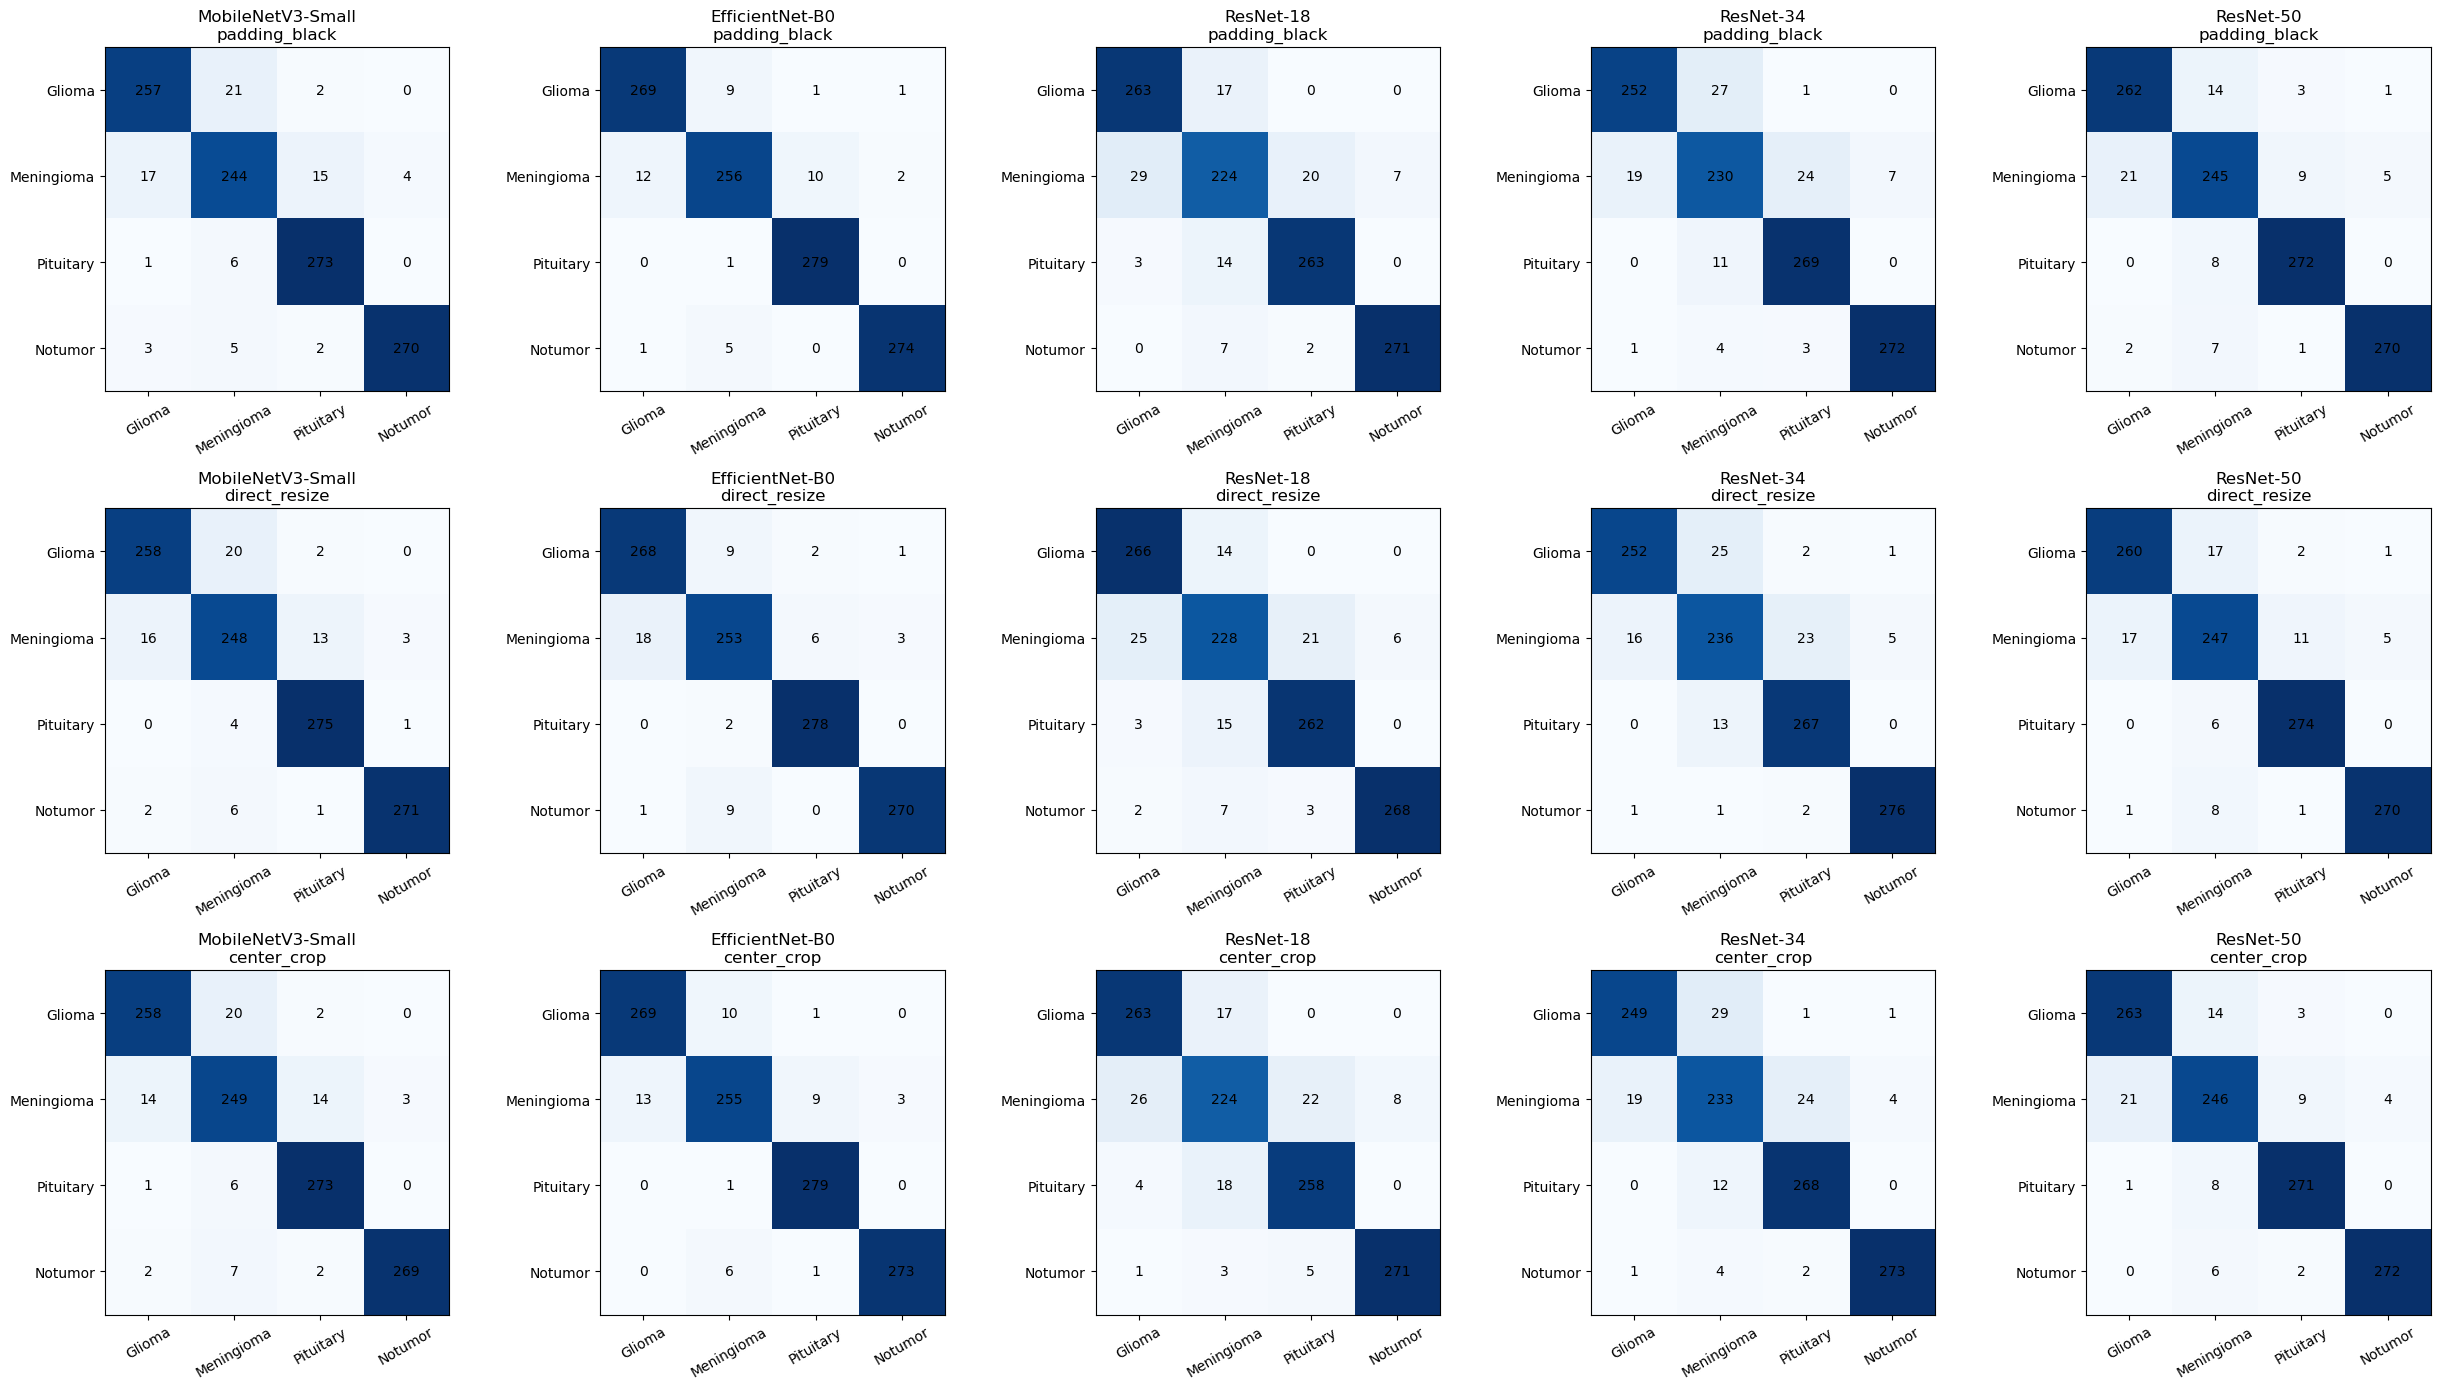

In [97]:
fig, axes = plt.subplots(3, 5, figsize=(25, 14))

row_number = 0
for option_name in option_names:
    col_number = 0
    for model_name in model_names:
        ax = axes[row_number][col_number]
        cm = confusion_matrix(grid_val_labels, grid_predictions[(option_name, model_name)])

        ax.imshow(cm, cmap="Blues")
        ax.set_title(model_name + "\n" + option_name)
        ax.set_xticks(range(4))
        ax.set_yticks(range(4))
        ax.set_xticklabels(classes, rotation=30)
        ax.set_yticklabels(classes)

        # write the numbers inside the boxes
        for r in range(4):
            for c in range(4):
                ax.text(c, r, cm[r][c], ha="center", va="center")

        col_number = col_number + 1
    row_number = row_number + 1

plt.tight_layout()
plt.show()

## Image Size and Padding Information

The width and height of every validation image are read first. From these, the amount of black padding each image would receive under the padding resize is calculated. This information is needed to check accuracy on the padded images, and to measure how much area center cropping removes.

In [99]:
# read the width and height of every validation image
def get_shape_info(dataframe):
    all_rows = []
    for i in range(len(dataframe)):
        path = dataframe.iloc[i]["File"]
        img = Image.open(path)
        w, h = img.size
        img.close()
        all_rows.append([w, h, w / h, w * h])
    return np.array(all_rows)

val_shapes = get_shape_info(val_data)
print("Val shapes:", val_shapes.shape)

Val shapes: (1120, 4)


### Black Padding per Image

This calculates how much of the 224 x 224 canvas would be black padding for each validation image under the padding resize. The resize shrinks images larger than 224 but never enlarges smaller ones, so small images also end up with padding. The table shows the average padding per class and how many images in each class get any padding at all.

In [107]:
# thumbnail only shrinks images, it never makes them bigger
def padding_fraction(w, h):
    size = 224
    scale = size / max(w, h)
    if scale > 1:
        scale = 1
    new_w = int(w * scale)
    new_h = int(h * scale)
    used_area = new_w * new_h
    return 1 - used_area / (size * size)

val_pad = []
for i in range(len(val_shapes)):
    val_pad.append(padding_fraction(val_shapes[i][0], val_shapes[i][1]))
val_pad = np.array(val_pad)

pad_table = pd.DataFrame({
    "Class": val_data["Class"].values,
    "Padding": val_pad
})
pad_table["Has_Padding"] = pad_table["Padding"] > 0.001

print("Average padding fraction per class:")
print(pad_table.groupby("Class")["Padding"].mean().round(4))
print()
print("Number of validation images with padding, per class:")
print(pad_table.groupby("Class")["Has_Padding"].sum())

Average padding fraction per class:
Class
Glioma        0.0000
Meningioma    0.0112
Notumor       0.1029
Pituitary     0.0032
Name: Padding, dtype: float64

Number of validation images with padding, per class:
Class
Glioma          0
Meningioma     26
Notumor       197
Pituitary      12
Name: Has_Padding, dtype: int64


### Accuracy on the Images That Get Padding

This addresses the aspect-ratio shortcut directly. With black padding, only some images get black bars, and the earlier shortcut check showed that most of them are No tumor images. If a model leans on the bars, its accuracy on the padded images will look different under padding than under the resize options without bars. This table shows accuracy on only the validation images that would receive padding, for every model and resize option.

In [108]:
# needs val_pad from the "Black Padding per Image" cell in Step 1
padded_rows = []

for option_name in option_names:
    for model_name in model_names:
        preds = grid_predictions[(option_name, model_name)]

        padded_correct = 0
        padded_total = 0
        for i in range(n_val):
            if val_pad[i] > 0.001:
                padded_total = padded_total + 1
                if preds[i] == grid_val_labels[i]:
                    padded_correct = padded_correct + 1

        padded_rows.append({
            "Resize": option_name,
            "Model": model_name,
            "Padded images": padded_total,
            "Accuracy on padded images (%)": round(padded_correct / padded_total * 100, 2)
        })

padded_table = pd.DataFrame(padded_rows)
padded_table.pivot(index="Model", columns="Resize", values="Accuracy on padded images (%)")

Resize,center_crop,direct_resize,padding_black
Model,,,
EfficientNet-B0,97.02,95.74,97.02
MobileNetV3-Small,95.32,96.17,95.74
ResNet-18,93.19,93.62,94.47
ResNet-34,93.62,94.47,92.77
ResNet-50,95.32,94.89,94.89


### Is the Top Model Significantly Better? (McNemar Test)

The best combination is chosen by macro F1. It is then compared with every other combination using McNemar's test. All models are tested on the same validation images, so the results are paired, and the test only looks at images where exactly one of the two models is right. If the two models were equally good, those disagreements would split about 50/50. A small p-value means the difference is unlikely to be chance.

In [109]:
from scipy.stats import binomtest

# the best combination is chosen by macro F1, not accuracy
best_row = grid_table.sort_values("Macro F1", ascending=False).iloc[0]
best_key = (best_row["Resize"], best_row["Model"])
print("Best combination by macro F1:", best_key)
print()

for key in grid_predictions:
    if key == best_key:
        continue

    best_only = 0    # best is right, other is wrong
    other_only = 0   # other is right, best is wrong

    for i in range(n_val):
        true_label = grid_val_labels[i]
        best_is_right = grid_predictions[best_key][i] == true_label
        other_is_right = grid_predictions[key][i] == true_label

        if best_is_right and not other_is_right:
            best_only = best_only + 1
        if other_is_right and not best_is_right:
            other_only = other_only + 1

    # if the two were equally good, the disagreements would split 50/50
    if best_only + other_only > 0:
        p_value = binomtest(best_only, best_only + other_only, 0.5).pvalue
    else:
        p_value = 1.0

    print(key, "| best only:", best_only, "| other only:", other_only, "| p-value:", round(p_value, 4))

Best combination by macro F1: ('padding_black', 'EfficientNet-B0')

('padding_black', 'MobileNetV3-Small') | best only: 54 | other only: 20 | p-value: 0.0001
('padding_black', 'ResNet-18') | best only: 72 | other only: 15 | p-value: 0.0
('padding_black', 'ResNet-34') | best only: 71 | other only: 16 | p-value: 0.0
('padding_black', 'ResNet-50') | best only: 50 | other only: 21 | p-value: 0.0008
('direct_resize', 'MobileNetV3-Small') | best only: 49 | other only: 23 | p-value: 0.0029
('direct_resize', 'EfficientNet-B0') | best only: 14 | other only: 5 | p-value: 0.0636
('direct_resize', 'ResNet-18') | best only: 68 | other only: 14 | p-value: 0.0
('direct_resize', 'ResNet-34') | best only: 66 | other only: 19 | p-value: 0.0
('direct_resize', 'ResNet-50') | best only: 50 | other only: 23 | p-value: 0.0021
('center_crop', 'MobileNetV3-Small') | best only: 52 | other only: 23 | p-value: 0.0011
('center_crop', 'EfficientNet-B0') | best only: 6 | other only: 4 | p-value: 0.7539
('center_crop

## Shortcut Check: Does Image Shape Alone Predict the Class?

During the midterm, it was pointed out that padding keeps the aspect-ratio signal visible to the model as black bars, and the earlier metadata check had already flagged this. Before changing anything, this section measures how much image shape alone says about the class.

The first step reads the width, height, aspect ratio and pixel count of every training and validation image.

In [110]:
classes = ["Glioma", "Meningioma", "Pituitary", "Notumor"]

def get_shape_info(dataframe):
    all_rows = []
    for i in range(len(dataframe)):
        path = dataframe.iloc[i]["File"]
        img = Image.open(path)
        w, h = img.size
        img.close()
        all_rows.append([w, h, w / h, w * h])
    return np.array(all_rows)

train_shapes = get_shape_info(train_data)
val_shapes = get_shape_info(val_data)

train_y = train_data["Class"].map(class_to_idx).values
val_y = val_data["Class"].map(class_to_idx).values

print("Train shapes:", train_shapes.shape)
print("Val shapes:", val_shapes.shape)

Train shapes: (4480, 4)
Val shapes: (1120, 4)


### Shape-Only Classifiers

Two simple classifiers are trained that only see the four shape numbers (width, height, aspect ratio, pixel count). They never see the pixels. Random guessing on four balanced classes would give about 25% accuracy. If these classifiers do much better than that, image shape leaks the class and a CNN could use it as a shortcut.

A logistic regression picks up smooth trends. A decision tree can pick up exact sizes such as 512 x 512, so it is the stronger test.

In [111]:
# logistic regression (needs scaled numbers)
scaler = StandardScaler()
train_shapes_scaled = scaler.fit_transform(train_shapes)
val_shapes_scaled = scaler.transform(val_shapes)

shape_logreg = LogisticRegression(max_iter=2000, random_state=42)
shape_logreg.fit(train_shapes_scaled, train_y)
logreg_preds = shape_logreg.predict(val_shapes_scaled)
logreg_acc = accuracy_score(val_y, logreg_preds)

# decision tree (can pick up exact sizes like 512 x 512)
shape_tree = DecisionTreeClassifier(max_depth=5, random_state=42)
shape_tree.fit(train_shapes, train_y)
tree_preds = shape_tree.predict(val_shapes)
tree_acc = accuracy_score(val_y, tree_preds)

print("Random guessing would get about 0.25")
print("Shape-only logistic regression accuracy:", round(logreg_acc, 4))
print("Shape-only decision tree accuracy:", round(tree_acc, 4))
print()
print("Decision tree per-class report:")
print(classification_report(val_y, tree_preds, target_names=classes, digits=3, zero_division=0))

Random guessing would get about 0.25
Shape-only logistic regression accuracy: 0.4509
Shape-only decision tree accuracy: 0.5062

Decision tree per-class report:
              precision    recall  f1-score   support

      Glioma      0.351     1.000     0.519       280
  Meningioma      0.500     0.021     0.041       280
   Pituitary      0.889     0.029     0.055       280
     Notumor      0.907     0.975     0.940       280

    accuracy                          0.506      1120
   macro avg      0.662     0.506     0.389      1120
weighted avg      0.662     0.506     0.389      1120



### Accuracy by Class on Padded vs Unpadded Images

This splits the validation accuracy of EfficientNet-B0 by class and by whether the image would receive padding. If padding works as a shortcut, accuracy on the padded images would look different from accuracy on the unpadded ones, especially for Notumor, since most padded images are Notumor.

The split is shown for all three resize options. If a model relied on the black bars, its accuracy on padded images would drop when the bars are removed (direct resize and center crop).

In [113]:
# which validation images would get padding
has_padding = val_pad > 0.001

for option_name in option_names:
    preds = grid_predictions[(option_name, "EfficientNet-B0")]

    check_table = pd.DataFrame({
        "Class": val_data["Class"].values,
        "True": grid_val_labels,
        "Pred": preds,
        "Has_Padding": has_padding
    })
    check_table["Correct"] = check_table["True"] == check_table["Pred"]

    print("Resize option:", option_name)
    print(check_table.groupby(["Class", "Has_Padding"])["Correct"].agg(["count", "mean"]).round(4))
    print()

Resize option: padding_black
                        count    mean
Class      Has_Padding               
Glioma     False          280  0.9607
Meningioma False          254  0.9173
           True            26  0.8846
Notumor    False           83  0.9759
           True           197  0.9797
Pituitary  False          268  0.9963
           True            12  1.0000

Resize option: direct_resize
                        count    mean
Class      Has_Padding               
Glioma     False          280  0.9571
Meningioma False          254  0.9094
           True            26  0.8462
Notumor    False           83  0.9518
           True           197  0.9695
Pituitary  False          268  0.9925
           True            12  1.0000

Resize option: center_crop
                        count    mean
Class      Has_Padding               
Glioma     False          280  0.9607
Meningioma False          254  0.9134
           True            26  0.8846
Notumor    False           83  0.9639
 

In [114]:
for option_name in option_names:
    preds = grid_predictions[(option_name, "EfficientNet-B0")]

    padded_correct = 0
    padded_total = 0
    for i in range(n_val):
        if val_pad[i] > 0.001:
            padded_total = padded_total + 1
            if preds[i] == grid_val_labels[i]:
                padded_correct = padded_correct + 1

    low, high = wilson_ci(padded_correct, padded_total)
    print(option_name, "| padded images:", padded_total,
          "| accuracy:", round(padded_correct / padded_total * 100, 2),
          "| 95% CI:", round(low * 100, 2), "to", round(high * 100, 2))

padding_black | padded images: 235 | accuracy: 97.02 | 95% CI: 93.98 to 98.55
direct_resize | padded images: 235 | accuracy: 95.74 | 95% CI: 92.35 to 97.67
center_crop | padded images: 235 | accuracy: 97.02 | 95% CI: 93.98 to 98.55


## Find the validation images that would get padding

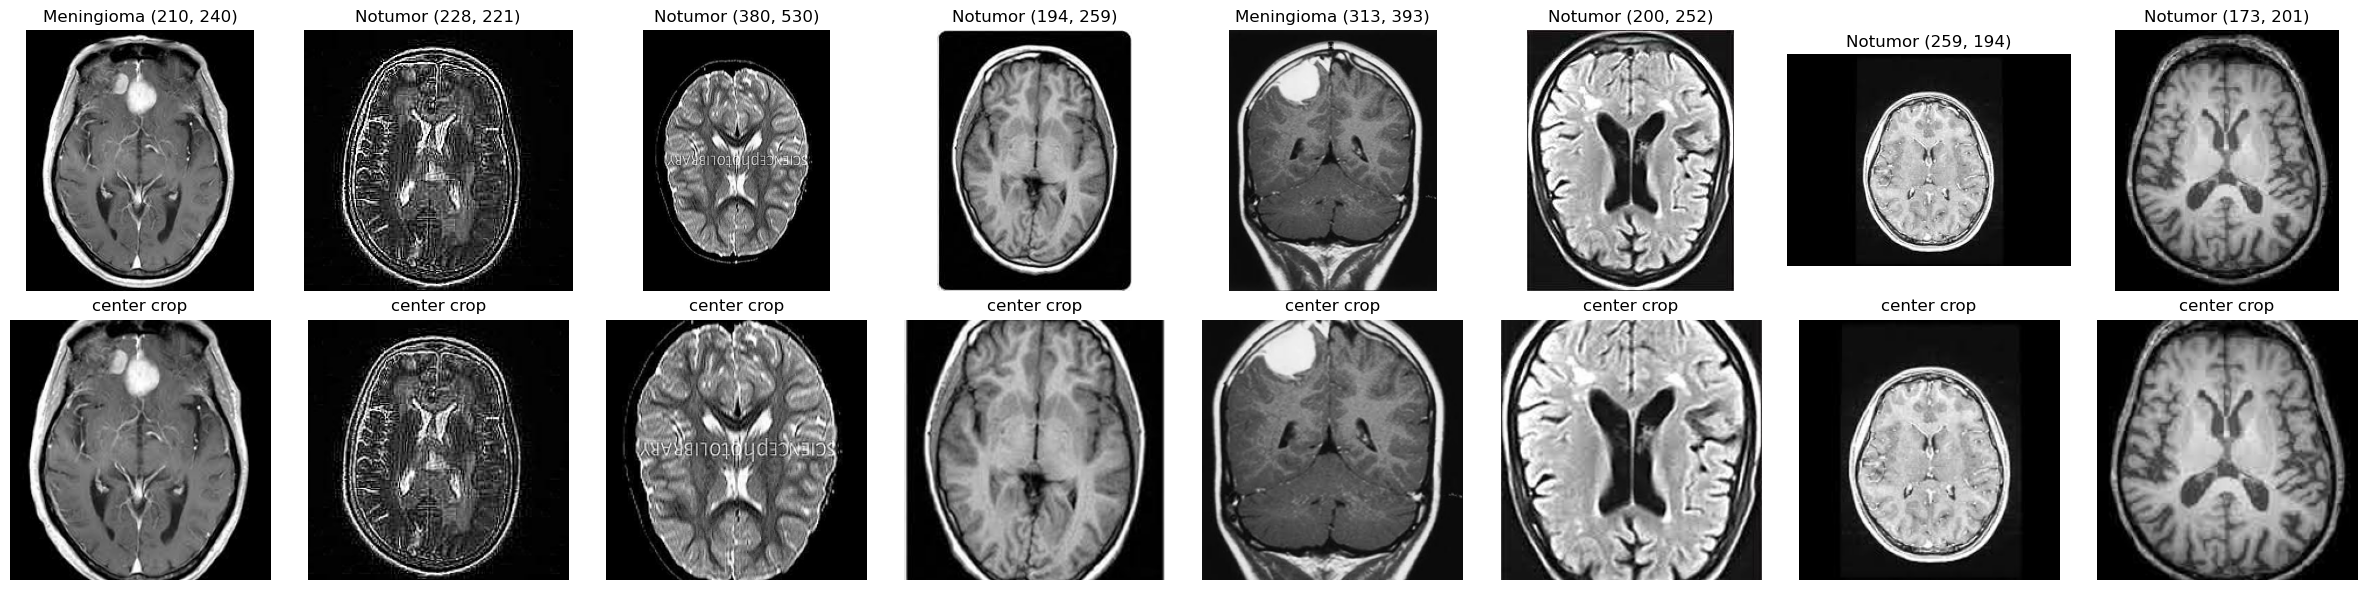

In [115]:
# find the validation images that would get padding
padded_positions = []
for i in range(len(val_pad)):
    if val_pad[i] > 0.001:
        padded_positions.append(i)

# take 8 of them spread across the list
chosen_positions = padded_positions[::30][:8]

fig, axes = plt.subplots(2, 8, figsize=(24, 6))

col = 0
for position in chosen_positions:
    path = val_data.iloc[position]["File"]
    original = Image.open(path).convert("RGB")
    cropped = resize_options["center_crop"](original)

    axes[0][col].imshow(original)
    axes[0][col].set_title(val_data.iloc[position]["Class"] + " " + str(original.size))
    axes[0][col].axis("off")

    axes[1][col].imshow(cropped)
    axes[1][col].set_title("center crop")
    axes[1][col].axis("off")

    col = col + 1

plt.tight_layout()
plt.show()

## How much of each image does the center crop throw away?

In [116]:
# how much of each image does the center crop throw away?
crop_loss = []
for i in range(len(val_shapes)):
    w = val_shapes[i][0]
    h = val_shapes[i][1]
    side = min(w, h)
    kept_area = side * side
    total_area = w * h
    crop_loss.append(1 - kept_area / total_area)
crop_loss = np.array(crop_loss)

loss_table = pd.DataFrame({
    "Class": val_data["Class"].values,
    "Crop_Loss": crop_loss
})
loss_table["Loses_over_20_percent"] = loss_table["Crop_Loss"] > 0.20

print("Average share of the image removed by center crop, per class:")
print(loss_table.groupby("Class")["Crop_Loss"].mean().round(4))
print()
print("Largest loss per class:")
print(loss_table.groupby("Class")["Crop_Loss"].max().round(4))
print()
print("Images losing more than 20% of their area, per class:")
print(loss_table.groupby("Class")["Loses_over_20_percent"].sum())

Average share of the image removed by center crop, per class:
Class
Glioma        0.0000
Meningioma    0.0108
Notumor       0.0887
Pituitary     0.0020
Name: Crop_Loss, dtype: float64

Largest loss per class:
Class
Glioma        0.0000
Meningioma    0.3194
Notumor       0.4400
Pituitary     0.1767
Name: Crop_Loss, dtype: float64

Images losing more than 20% of their area, per class:
Class
Glioma         0
Meningioma     3
Notumor       40
Pituitary      0
Name: Loses_over_20_percent, dtype: int64


### Final Model Selection Rationale

**Scope of the comparison.** Five candidate architectures (MobileNetV3-Small, EfficientNet-B0, ResNet-18, ResNet-34 and ResNet-50) were compared under three resize options (black padding, direct resizing and center cropping), giving 15 configurations. Each used frozen ImageNet features and the same logistic regression classifier. The validation set (1,120 images, 280 per class) was used for every comparison, and the held-out test set was not touched. Candidates were compared on accuracy, macro precision, macro recall and macro F1, together with per-class results and confusion matrices, so that no model was selected on accuracy alone.

**Why these candidates.** The five models span about 2.5 million to 25 million parameters and two design families (efficient scaled networks and residual networks). ResNet-18 came from the original proposal and is the smallest ResNet. ResNet-34 and ResNet-50 were added after the midterm feedback, which pointed out that ResNet-18 is the weakest ResNet, so that deeper residual networks were tested and not simply assumed to be worse.

**Model choice.** EfficientNet-B0 had the best average rank (1.0) across the four metrics within each resize configuration, so it ranked first among all five models, including the deeper ResNet-34 and ResNet-50. Its best macro F1 was 0.9623 (black padding), and with center cropping it reached 0.9605. EfficientNet-B0 is also far cheaper than the deeper ResNets: 5.29 million parameters and 0.39 GFLOPs, compared with 21.80 and 25.56 million parameters and 3.66 and 4.09 GFLOPs for ResNet-34 and ResNet-50. It therefore gave the best measured performance at the lowest cost among the strong candidates. This matters because the selected model is reused for training, clean testing and repeated noise and blur testing.

**Resize choice: evidence of a shortcut.** The earlier shape-only check showed that image dimensions alone, with no pixel information, predicted the class with 45.09% accuracy (logistic regression) and 50.62% (decision tree), against 25% for random guessing. Image shape therefore carries a real class-associated signal. Black padding keeps that signal visible to the CNN as black bars, so a model could partly rely on it. Shape does not reliably separate all four classes, so the risk is real but not complete.

**Resize choice: padding gives no measurable benefit.** On the 235 validation images that receive padding, EfficientNet-B0 scored 97.02% (95% CI 93.98 to 98.55) with black padding, 97.02% (93.98 to 98.55) with center cropping, and 95.74% (92.35 to 97.67) with direct resizing. The intervals overlap heavily, so padding does not do measurably better on the images it affects. Overall, EfficientNet-B0 with center cropping (macro F1 = 0.9605) was not significantly different from EfficientNet-B0 with black padding (macro F1 = 0.9623; McNemar p = 0.7539). The decision rule written before the results were seen said to prefer a resize without black bars if it performed about as well as padding. Center cropping meets that rule. Direct resizing also removes the bars, but it stretches the anatomy and had the lowest accuracy on the padded images, so it was not preferred.

**Resize choice: cost of cropping.** Cropping removes the edges of non-square images, so the information loss was measured for every validation image. Glioma images are square and lose nothing. Pituitary images lose 0.2% of their area on average (worst case 17.7%) and Meningioma images 1.1% (worst case 31.9%). Only 3 of the 840 tumor-class validation images lose more than 20% of their area. The loss falls mainly on Notumor images (average 8.9%, worst case 44%, 40 images above 20%), which contain no tumor that could be cut off. Eight sample padded images were also inspected before and after cropping, and the brain stayed fully in the frame in each.

**Decision.** EfficientNet-B0 with center-crop resizing is selected as the final configuration. It has the best measured performance of the five candidates, it is the cheapest of the strong models, and it removes the black-bar shortcut flagged after the midterm presentation without a measurable loss in performance.

**Limitations.** Center cropping removes more area from Notumor images than from the tumor classes, so a weak class-dependent signal may remain even without black bars, and cropping does not remove aspect-ratio information completely because the original shape can still show through. The comparison used frozen features with a logistic regression classifier, so the ranking could change after fine-tuning, and the final model is therefore evaluated again after fine-tuning. Confidence intervals on overall accuracy are based on 1,120 images, per-class intervals on 280 images each, and the padded-image intervals on 235 images, so per-class and padded-subset intervals are wider than the overall ones.

## Normalization Ablation (Final Configuration)

The resize question was settled in the model comparison, so the remaining preprocessing question is normalization. The earlier normalization test used ResNet-18 and padded images. It is repeated here with the selected model (EfficientNet-B0) and the selected resize (center crop).

Two options are compared:
1. ImageNet normalization (the statistics the pretrained model was trained with)
2. Dataset-specific normalization (mean and standard deviation of the center-cropped training images)

Decision rule, set before looking at the results: ImageNet normalization is kept unless dataset-specific normalization is significantly better, because the pretrained weights were trained with ImageNet statistics. Only the training and validation sets are used.

### Dataset Statistics on Center-Cropped Images

The earlier dataset mean and standard deviation were calculated on padded images, so the black bars pulled the values down. The statistics are recalculated here on the center-cropped training images only. Every training image is cropped, its pixel values are added up for the red, green and blue channels, and the mean and standard deviation are worked out from those totals.

In [117]:
# add up the pixel values of every training image after the center crop
channel_sum = np.zeros(3)
channel_sum_squared = np.zeros(3)
pixel_count = 0

for i in range(len(train_data)):
    path = train_data.iloc[i]["File"]
    image = Image.open(path).convert("RGB")
    cropped = resize_options["center_crop"](image)
    pixels = np.array(cropped) / 255.0     # values between 0 and 1

    channel_sum = channel_sum + pixels.sum(axis=(0, 1))
    channel_sum_squared = channel_sum_squared + (pixels ** 2).sum(axis=(0, 1))
    pixel_count = pixel_count + pixels.shape[0] * pixels.shape[1]

# mean and standard deviation for the R, G and B channels
crop_mean = channel_sum / pixel_count
crop_std = np.sqrt(channel_sum_squared / pixel_count - crop_mean ** 2)

crop_mean = crop_mean.tolist()
crop_std = crop_std.tolist()

print("Center-crop dataset mean:", [round(x, 4) for x in crop_mean])
print("Center-crop dataset std:", [round(x, 4) for x in crop_std])
print()
print("ImageNet mean:", imagenet_mean)
print("ImageNet std:", imagenet_std)

Center-crop dataset mean: [0.1893, 0.1893, 0.1893]
Center-crop dataset std: [0.2031, 0.2031, 0.2032]

ImageNet mean: [0.485, 0.456, 0.406]
ImageNet std: [0.229, 0.224, 0.225]


### Extract Features With Dataset-Specific Normalization

EfficientNet-B0 features are extracted from the center-cropped images using the dataset-specific mean and standard deviation. The ImageNet-normalized center-crop features were already extracted in the model comparison, so they are reused and not extracted again. The features are saved to disk so this step does not need to be repeated.

In [118]:
dataset_norm_transform = transforms.Compose([
    transforms.Lambda(lambda image: image.convert("RGB")),
    resize_options["center_crop"],
    transforms.ToTensor(),
    transforms.Normalize(crop_mean, crop_std)
])

norm_train_dataset = BrainTumorDataset(train_data, transform=dataset_norm_transform)
norm_val_dataset = BrainTumorDataset(val_data, transform=dataset_norm_transform)

norm_train_loader = DataLoader(norm_train_dataset, batch_size=32, shuffle=False, num_workers=0)
norm_val_loader = DataLoader(norm_val_dataset, batch_size=32, shuffle=False, num_workers=0)

dataset_train_feats, train_labs_check = get_or_extract_features(
    extractors["EfficientNet-B0"], norm_train_loader,
    "norm_dataset_center_crop_efficientnetb0", "train", device)

dataset_val_feats, val_labs_check = get_or_extract_features(
    extractors["EfficientNet-B0"], norm_val_loader,
    "norm_dataset_center_crop_efficientnetb0", "val", device)

print("Train features:", dataset_train_feats.shape)
print("Val features:", dataset_val_feats.shape)

Extracting features for norm_dataset_center_crop_efficientnetb0 train ...
Saved: norm_dataset_center_crop_efficientnetb0_train.npz
Extracting features for norm_dataset_center_crop_efficientnetb0 val ...
Saved: norm_dataset_center_crop_efficientnetb0_val.npz
Train features: (4480, 1280)
Val features: (1120, 1280)


### Compare the Two Normalization Options

The same logistic regression classifier is trained on the features from each normalization option and tested on the validation set. The table reports overall accuracy with its 95% confidence interval, plus macro precision, macro recall and macro F1. The confidence interval is for overall accuracy and is based on all 1,120 validation images.

In [119]:
# ImageNet normalization features were already extracted in the model comparison
imagenet_train_feats = grid_train[("center_crop", "EfficientNet-B0")]
imagenet_val_feats = grid_val[("center_crop", "EfficientNet-B0")]

def score_features(name, train_feats, val_feats):
    clf = LogisticRegression(max_iter=2000, random_state=42)
    clf.fit(train_feats, grid_train_labels)
    preds = clf.predict(val_feats)

    # count how many the model got right
    correct = 0
    for i in range(n_val):
        if preds[i] == grid_val_labels[i]:
            correct = correct + 1

    low, high = wilson_ci(correct, n_val)
    prec, rec, f1, _ = precision_recall_fscore_support(
        grid_val_labels, preds, average="macro", zero_division=0)

    row = {
        "Normalization": name,
        "Accuracy (%)": round(correct / n_val * 100, 2),
        "Acc CI low": round(low * 100, 2),
        "Acc CI high": round(high * 100, 2),
        "Macro Precision": round(prec, 4),
        "Macro Recall": round(rec, 4),
        "Macro F1": round(f1, 4)
    }
    return preds, row

imagenet_preds, imagenet_row = score_features(
    "ImageNet normalization", imagenet_train_feats, imagenet_val_feats)

dataset_preds, dataset_row = score_features(
    "Dataset-specific normalization", dataset_train_feats, dataset_val_feats)

norm_table = pd.DataFrame([imagenet_row, dataset_row])
print("The CI is for OVERALL accuracy on", n_val, "validation images")
norm_table

The CI is for OVERALL accuracy on 1120 validation images


,Normalization,Accuracy (%),Acc CI low,Acc CI high,Macro Precision,Macro Recall,Macro F1
0,ImageNet normalization,96.07,94.77,97.06,0.9607,0.9607,0.9605
1,Dataset-specific normalization,94.20,92.67,95.42,0.9424,0.9420,0.9420


### Is the Difference Significant? (McNemar Test)

Both normalization options are tested on the same validation images, so the results are paired and the McNemar test is used again. The test only looks at images where exactly one of the two options is right. If the two options were equally good, those disagreements would split about 50/50. A small p-value means the difference is unlikely to be chance.

In [120]:
imagenet_only = 0    # ImageNet right, dataset-specific wrong
dataset_only = 0     # dataset-specific right, ImageNet wrong

for i in range(n_val):
    true_label = grid_val_labels[i]
    imagenet_is_right = imagenet_preds[i] == true_label
    dataset_is_right = dataset_preds[i] == true_label

    if imagenet_is_right and not dataset_is_right:
        imagenet_only = imagenet_only + 1
    if dataset_is_right and not imagenet_is_right:
        dataset_only = dataset_only + 1

# if both were equally good, the disagreements would split 50/50
if imagenet_only + dataset_only > 0:
    p_value = binomtest(imagenet_only, imagenet_only + dataset_only, 0.5).pvalue
else:
    p_value = 1.0

print("ImageNet only right:", imagenet_only)
print("Dataset-specific only right:", dataset_only)
print("p-value:", round(p_value, 4))

ImageNet only right: 44
Dataset-specific only right: 23
p-value: 0.0139


## Normalization Decision

ImageNet normalization reached an overall accuracy of 96.07% (95% CI 94.77 to 97.06) and a macro F1 of 0.9605. Dataset-specific normalization, using the mean and standard deviation of the center-cropped training images, reached 94.20% (95% CI 92.67 to 95.42) and a macro F1 of 0.9420. ImageNet normalization was correct where dataset-specific normalization was wrong on 44 validation images, while the reverse happened on 23 images (McNemar p = 0.0139). The two accuracy intervals overlap slightly, but the paired test compares the two options on the same images and is more sensitive than comparing the intervals.

Following the decision rule set before the results, ImageNet normalization is kept, because dataset-specific normalization was not better and was in fact significantly worse. A likely reason is that the pretrained weights were trained with ImageNet statistics, so matching them matters more than matching the MRI statistics. The final preprocessing is therefore center-crop resizing with ImageNet normalization.

# FINAL TRAINING

## Final Model Training

The selected configuration (EfficientNet-B0, center-crop resizing, ImageNet normalization) is trained in two stages:

1. **Stage 1, classification head only:** the pretrained feature layers are frozen and only the new four-class layer is trained.
2. **Stage 2, fine-tuning:** the last three feature blocks are unfrozen and trained together with the classification layer, using a smaller learning rate.

**Stopping rule (same for both stages).** The number of epochs is not fixed in advance. After every epoch the model is checked on the validation set, and training stops when validation loss has not improved by at least 0.001 for 5 epochs in a row. A patience of 5 was chosen because in the first stage 1 run validation loss never failed to improve for more than one epoch in a row, so 5 epochs leaves a large margin against random fluctuation, while a much larger patience would add many slow CPU epochs after the best one. A hard limit of 100 epochs exists only as a safeguard against a run that never stops. The checkpoint with the lowest validation loss is kept.

Validation loss is used as the monitor because it is smoother than accuracy or F1. Validation accuracy and macro F1 are recorded every epoch and reported for the best checkpoint. If validation loss rises while training loss keeps falling, the model is overfitting, and the best checkpoint protects against that.

The training set (4,480 images) is used for learning and the validation set (1,120 images) for monitoring and for choosing the best checkpoint. The held-out test set is not used until the final evaluation.

### Stage 1: Train the Classification Head

Only the new classification layer is trained, with a learning rate of 0.001. This is a common starting value for a new layer on top of frozen features and was not tuned. All nine feature blocks are kept in evaluation mode.

Training stops when validation loss has not improved by at least 0.001 for 5 epochs in a row. After every epoch the training loss and accuracy and the validation loss, accuracy and macro F1 are recorded so that learning curves can be plotted later. The checkpoint with the lowest validation loss is saved and reloaded at the end.

In [135]:
history = {
    "stage": [], "epoch": [],
    "train_loss": [], "train_acc": [],
    "val_loss": [], "val_acc": [], "val_f1": []
}

head_optimizer = torch.optim.Adam(final_model.classifier.parameters(), lr=0.001)

all_blocks = [0, 1, 2, 3, 4, 5, 6, 7, 8]   # every feature block is frozen in stage 1

max_epochs = 100        # only a safety limit, early stopping should stop it first
patience = 5            # stop if no improvement for this many epochs in a row
min_delta = 0.001       # an improvement must be at least this big to count

best_val_loss = 999
best_val_acc = 0
best_val_f1 = 0
best_epoch = 0
epochs_without_improvement = 0

for epoch in range(1, max_epochs + 1):
    start_time = time.time()

    train_loss, train_acc = train_one_epoch(final_model, train_loader, head_optimizer, all_blocks)
    val_loss, val_acc, val_preds, val_true = evaluate(final_model, val_loader)
    val_f1 = f1_score(val_true, val_preds, average="macro")

    history["stage"].append(1)
    history["epoch"].append(epoch)
    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)
    history["val_f1"].append(val_f1)

    minutes = (time.time() - start_time) / 60
    print("Stage 1, epoch", epoch, "| train loss:", round(train_loss, 4),
          "| train acc:", round(train_acc, 4), "| val loss:", round(val_loss, 4),
          "| val acc:", round(val_acc, 4), "| val macro F1:", round(val_f1, 4),
          "|", round(minutes, 1), "min")

    # did validation loss improve enough?
    if val_loss < best_val_loss - min_delta:
        best_val_loss = val_loss
        best_val_acc = val_acc
        best_val_f1 = val_f1
        best_epoch = epoch
        epochs_without_improvement = 0
        torch.save(final_model.state_dict(), "stage1_best.pt")
    else:
        epochs_without_improvement = epochs_without_improvement + 1

    # stop early if it has not improved for a while
    if epochs_without_improvement >= patience:
        print("Validation loss did not improve for", patience, "epochs. Stopping early.")
        break

# go back to the best checkpoint
final_model.load_state_dict(torch.load("stage1_best.pt"))
print()
print("Stage 1 best epoch:", best_epoch)
print("Validation loss at best epoch:", round(best_val_loss, 4))
print("Validation accuracy at best epoch:", round(best_val_acc, 4))
print("Validation macro F1 at best epoch:", round(best_val_f1, 4))

Stage 1, epoch 1 | train loss: 0.1789 | train acc: 0.9337 | val loss: 0.1971 | val acc: 0.9268 | val macro F1: 0.9261 | 3.7 min
Stage 1, epoch 2 | train loss: 0.167 | train acc: 0.9362 | val loss: 0.2012 | val acc: 0.9232 | val macro F1: 0.9236 | 3.6 min
Stage 1, epoch 3 | train loss: 0.173 | train acc: 0.9375 | val loss: 0.1954 | val acc: 0.9241 | val macro F1: 0.9238 | 3.5 min
Stage 1, epoch 4 | train loss: 0.1741 | train acc: 0.9337 | val loss: 0.1942 | val acc: 0.9268 | val macro F1: 0.9264 | 3.4 min
Stage 1, epoch 5 | train loss: 0.1669 | train acc: 0.9362 | val loss: 0.1982 | val acc: 0.9286 | val macro F1: 0.9282 | 3.4 min
Stage 1, epoch 6 | train loss: 0.1678 | train acc: 0.9371 | val loss: 0.1929 | val acc: 0.9241 | val macro F1: 0.9235 | 3.6 min
Stage 1, epoch 7 | train loss: 0.1636 | train acc: 0.9397 | val loss: 0.1807 | val acc: 0.9366 | val macro F1: 0.9367 | 3.6 min
Stage 1, epoch 8 | train loss: 0.1519 | train acc: 0.9455 | val loss: 0.1846 | val acc: 0.9304 | val macro

### Stage 2: Unfreeze the Last Three Feature Blocks

For fine-tuning, the last three blocks of the EfficientNet-B0 feature layers (blocks 6, 7 and 8) are unfrozen, together with the classification layer from stage 1. The early blocks stay frozen because they detect general patterns such as edges and textures, which transfer well to MRI images. The later blocks are more specific to the original ImageNet task, so they benefit most from adapting to MRI scans.

Unfreezing the last three blocks is a common choice and was not tuned. It keeps most of the pretrained network fixed, which limits the risk of overfitting on 4,480 training images. The number of trainable parameters is printed below.

In [136]:
# unfreeze the last three blocks of the feature layers (blocks 6, 7 and 8)
for block_number in [6, 7, 8]:
    for parameter in final_model.features[block_number].parameters():
        parameter.requires_grad = True

# count the parameters that can learn now
trainable = 0
for parameter in final_model.parameters():
    if parameter.requires_grad:
        trainable = trainable + parameter.numel()

print("Trainable parameters in stage 2:", trainable)

Trainable parameters in stage 2: 3160864


### Stage 2: Fine-Tune the Model

The unfrozen layers are trained with a learning rate of 0.0001, ten times smaller than in stage 1, so the pretrained weights are adjusted gently and not overwritten. This is a common starting value for fine-tuning and was not tuned. The early blocks (0 to 5) are kept in evaluation mode.

The stopping rule is the same as in stage 1: training stops when validation loss has not improved by at least 0.001 for 5 epochs in a row, with a safety limit of 100 epochs, and the checkpoint with the lowest validation loss is kept. The stage 1 model is the starting point, so if fine-tuning never beats the stage 1 validation loss, the stage 1 model is kept. The held-out test set is not used in any decision.

In [137]:
# collect the parameters that are allowed to learn
trainable_params = []
for parameter in final_model.parameters():
    if parameter.requires_grad:
        trainable_params.append(parameter)

finetune_optimizer = torch.optim.Adam(trainable_params, lr=0.0001)

early_blocks = [0, 1, 2, 3, 4, 5]    # these stay frozen in stage 2

max_epochs_2 = 100       # only a safety limit
patience_2 = 5
min_delta_2 = 0.001

# the stage 1 result is the number to beat
best_val_loss_2 = best_val_loss
best_val_acc_2 = best_val_acc
best_val_f1_2 = best_val_f1
best_epoch_2 = 0
epochs_without_improvement_2 = 0

# save the stage 1 model as the starting "best" model
torch.save(final_model.state_dict(), "stage2_best.pt")

for epoch in range(1, max_epochs_2 + 1):
    start_time = time.time()

    train_loss, train_acc = train_one_epoch(final_model, train_loader, finetune_optimizer, early_blocks)
    val_loss, val_acc, val_preds, val_true = evaluate(final_model, val_loader)
    val_f1 = f1_score(val_true, val_preds, average="macro")

    history["stage"].append(2)
    history["epoch"].append(epoch)
    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)
    history["val_f1"].append(val_f1)

    minutes = (time.time() - start_time) / 60
    print("Stage 2, epoch", epoch, "| train loss:", round(train_loss, 4),
          "| train acc:", round(train_acc, 4), "| val loss:", round(val_loss, 4),
          "| val acc:", round(val_acc, 4), "| val macro F1:", round(val_f1, 4),
          "|", round(minutes, 1), "min")

    # did validation loss improve enough?
    if val_loss < best_val_loss_2 - min_delta_2:
        best_val_loss_2 = val_loss
        best_val_acc_2 = val_acc
        best_val_f1_2 = val_f1
        best_epoch_2 = epoch
        epochs_without_improvement_2 = 0
        torch.save(final_model.state_dict(), "stage2_best.pt")
    else:
        epochs_without_improvement_2 = epochs_without_improvement_2 + 1

    # stop early if it has not improved for a while
    if epochs_without_improvement_2 >= patience_2:
        print("Validation loss did not improve for", patience_2, "epochs. Stopping early.")
        break

# go back to the best checkpoint
final_model.load_state_dict(torch.load("stage2_best.pt"))
print()
print("Stage 2 best epoch:", best_epoch_2, "(0 means stage 1 was never beaten)")
print("Validation loss at best epoch:", round(best_val_loss_2, 4))
print("Validation accuracy at best epoch:", round(best_val_acc_2, 4))
print("Validation macro F1 at best epoch:", round(best_val_f1_2, 4))

Stage 2, epoch 1 | train loss: 0.209 | train acc: 0.919 | val loss: 0.1617 | val acc: 0.9411 | val macro F1: 0.9416 | 3.2 min
Stage 2, epoch 2 | train loss: 0.1161 | train acc: 0.9571 | val loss: 0.1237 | val acc: 0.9536 | val macro F1: 0.9534 | 3.1 min
Stage 2, epoch 3 | train loss: 0.07 | train acc: 0.9746 | val loss: 0.1953 | val acc: 0.9437 | val macro F1: 0.9438 | 3.1 min
Stage 2, epoch 4 | train loss: 0.0511 | train acc: 0.9828 | val loss: 0.1063 | val acc: 0.9598 | val macro F1: 0.9595 | 3.1 min
Stage 2, epoch 5 | train loss: 0.0378 | train acc: 0.9884 | val loss: 0.0927 | val acc: 0.967 | val macro F1: 0.9671 | 3.0 min
Stage 2, epoch 6 | train loss: 0.0349 | train acc: 0.9888 | val loss: 0.0994 | val acc: 0.9616 | val macro F1: 0.9617 | 3.0 min
Stage 2, epoch 7 | train loss: 0.0298 | train acc: 0.9904 | val loss: 0.0824 | val acc: 0.9741 | val macro F1: 0.9741 | 3.1 min
Stage 2, epoch 8 | train loss: 0.0266 | train acc: 0.9915 | val loss: 0.0814 | val acc: 0.9732 | val macro F1

### Stage 2 Results

Fine-tuning ran for 14 epochs and stopped early, because validation loss had not improved by at least 0.001 for 5 epochs in a row (epochs 10 to 14). The best checkpoint was epoch 9, with a validation loss of 0.0640, a validation accuracy of 97.59% and a validation macro F1 of 0.9759. Training accuracy at that epoch was 99.06%, about 1.5 percentage points above validation accuracy, so the model fits the training data slightly better than the validation data but not by a large margin.

After epoch 9 the training loss kept falling (0.0237 to 0.0155 at epoch 10) while the validation loss stayed around 0.064 and fluctuated between 0.0634 and 0.0766. This is the beginning of overfitting, and it is the reason the best checkpoint is kept and not the last epoch. A later epoch (epoch 12) reached a slightly higher validation accuracy of 98.04%, about 5 images more than epoch 9. The checkpoint was not changed, because the stopping rule was fixed before the results were seen and the difference is within the noise of a 1,120-image validation set.

The validation results are slightly optimistic, because the validation set was used to choose the stopping point and the checkpoint. The held-out test set gives the unbiased estimate.

### Does Fine-Tuning Beat the Frozen Baseline?

In the model comparison, the frozen EfficientNet-B0 features with logistic regression reached 96.07% validation accuracy (center crop, ImageNet normalization). The fine-tuned model is compared with it on the same validation images with a McNemar test. This checks whether the extra training stage made a real difference and was not just chance.

In [138]:
# predictions of the fine-tuned model on the validation set (same order as before)
ft_loss, ft_acc, ft_pred_list, ft_true_list = evaluate(final_model, val_loader)
finetuned_preds = ft_pred_list

print("Fine-tuned validation accuracy:", round(ft_acc, 4))

finetuned_only = 0   # fine-tuned right, frozen baseline wrong
frozen_only = 0      # frozen baseline right, fine-tuned wrong

for i in range(n_val):
    true_label = grid_val_labels[i]
    finetuned_is_right = finetuned_preds[i] == true_label
    frozen_is_right = imagenet_preds[i] == true_label

    if finetuned_is_right and not frozen_is_right:
        finetuned_only = finetuned_only + 1
    if frozen_is_right and not finetuned_is_right:
        frozen_only = frozen_only + 1

if finetuned_only + frozen_only > 0:
    p_value = binomtest(finetuned_only, finetuned_only + frozen_only, 0.5).pvalue
else:
    p_value = 1.0

print("Fine-tuned only right:", finetuned_only)
print("Frozen baseline only right:", frozen_only)
print("p-value:", round(p_value, 4))

Fine-tuned validation accuracy: 0.9759
Fine-tuned only right: 31
Frozen baseline only right: 14
p-value: 0.0161


## Clean Test Set Evaluation

The final model is now evaluated once on the held-out test set. This set was not used for training, for model selection, for choosing the resize or normalization, or for choosing the stopping point and checkpoint, so these results are an unbiased estimate of performance on clean images. No further changes are made to the model after this evaluation.

### Predictions on the Test Set

The final model predicts the class of every test image. The loss, accuracy, predictions and true labels are stored for the metrics below.

In [139]:
test_loss, test_acc, test_pred_list, test_true_list = evaluate(final_model, test_loader)

test_preds = np.array(test_pred_list)
test_labels = np.array(test_true_list)
n_test = len(test_labels)

print("Test images:", n_test)
print("Test loss:", round(test_loss, 4))
print("Test accuracy:", round(test_acc, 4))

Test images: 1600
Test loss: 0.4124
Test accuracy: 0.9437


### Overall Test Metrics With a Confidence Interval

The overall accuracy is reported with a 95% confidence interval, together with macro precision, macro recall and macro F1. This confidence interval is for the **overall accuracy** and is based on all the test images. The per-class intervals in the next section are based only on the images of each class, so they are wider.

In [140]:
# count how many test images were classified correctly
correct = 0
for i in range(n_test):
    if test_preds[i] == test_labels[i]:
        correct = correct + 1

acc = correct / n_test
low, high = wilson_ci(correct, n_test)
prec, rec, f1, _ = precision_recall_fscore_support(
    test_labels, test_preds, average="macro", zero_division=0)

print("Correct:", correct, "out of", n_test)
print("Overall accuracy:", round(acc * 100, 2), "%")
print("95% CI for OVERALL accuracy:", round(low * 100, 2), "to", round(high * 100, 2))
print("Macro precision:", round(prec, 4))
print("Macro recall:", round(rec, 4))
print("Macro F1:", round(f1, 4))

Correct: 1510 out of 1600
Overall accuracy: 94.38 %
95% CI for OVERALL accuracy: 93.14 to 95.4
Macro precision: 0.9464
Macro recall: 0.9438
Macro F1: 0.9427


### Per-Class Test Metrics

Precision, recall and F1 are calculated for each tumor class. Recall is the share of the images of a class that the model found, and precision is the share of the images the model labeled as that class that really belong to it. The confidence interval is for the **recall of that class only**, based on the number of test images in that class (column N).

In [141]:
class_rows = []

for class_name in classes:
    c = class_to_idx[class_name]

    n_class = 0           # test images that truly belong to this class
    predicted_class = 0   # test images the model said are this class
    correct_class = 0     # test images it got right for this class

    for i in range(n_test):
        if test_labels[i] == c:
            n_class = n_class + 1
        if test_preds[i] == c:
            predicted_class = predicted_class + 1
        if test_labels[i] == c and test_preds[i] == c:
            correct_class = correct_class + 1

    recall = correct_class / n_class

    if predicted_class > 0:
        precision = correct_class / predicted_class
    else:
        precision = 0

    if precision + recall > 0:
        f1_class = 2 * precision * recall / (precision + recall)
    else:
        f1_class = 0

    low, high = wilson_ci(correct_class, n_class)

    class_rows.append({
        "Class": class_name,
        "N": n_class,
        "Precision": round(precision, 4),
        "Recall": round(recall, 4),
        "Recall CI low": round(low, 4),
        "Recall CI high": round(high, 4),
        "F1": round(f1_class, 4)
    })

test_class_table = pd.DataFrame(class_rows)
print("The CI here is for each CLASS's recall, based on N images in that class")
test_class_table

The CI here is for each CLASS's recall, based on N images in that class


,Class,N,Precision,Recall,Recall CI low,Recall CI high,F1
0,Glioma,400,0.9792,0.8225,0.7820,0.8568,0.8940
1,Meningioma,400,0.9102,0.9625,0.9391,0.9771,0.9356
2,Pituitary,400,0.9851,0.9900,0.9746,0.9961,0.9875
3,Notumor,400,0.9112,1.0000,0.9905,1.0000,0.9535


### Confusion Matrix on the Test Set

The confusion matrix shows how the test images were classified. Rows are the true classes and columns are the predicted classes. The numbers on the diagonal are correct predictions, and the numbers off the diagonal show which classes the model confuses.

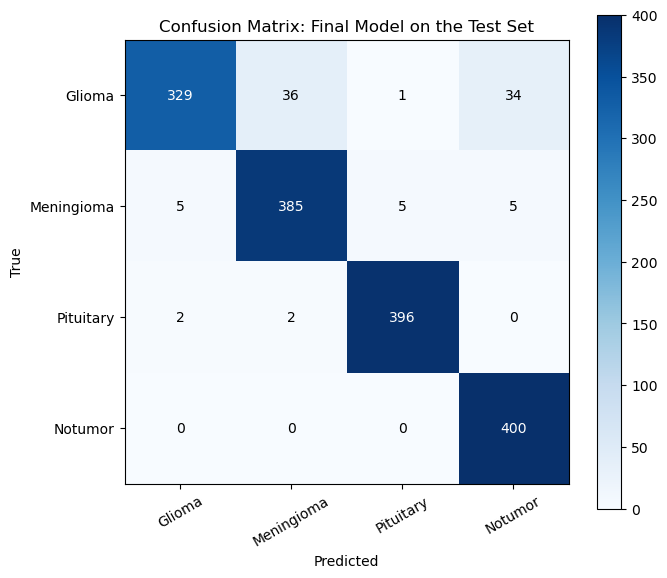

In [142]:
cm = confusion_matrix(test_labels, test_preds)

plt.figure(figsize=(7, 6))
plt.imshow(cm, cmap="Blues")
plt.title("Confusion Matrix: Final Model on the Test Set")
plt.xticks(range(4), classes, rotation=30)
plt.yticks(range(4), classes)
plt.xlabel("Predicted")
plt.ylabel("True")

# write the numbers inside the boxes
for r in range(4):
    for c in range(4):
        if cm[r][c] > cm.max() / 2:
            text_color = "white"
        else:
            text_color = "black"
        plt.text(c, r, cm[r][c], ha="center", va="center", color=text_color)

plt.colorbar()
plt.tight_layout()
plt.show()

### Most Common Mistakes

This table lists every kind of mistake the model made on the test set, from the most frequent to the least frequent. It shows which pairs of classes the model confuses.

In [144]:
error_counts = {}

for i in range(n_test):
    if test_labels[i] != test_preds[i]:
        pair = classes[test_labels[i]] + " predicted as " + classes[test_preds[i]]
        if pair in error_counts:
            error_counts[pair] = error_counts[pair] + 1
        else:
            error_counts[pair] = 1

error_rows = []
for pair in error_counts:
    error_rows.append({"Mistake": pair, "Count": error_counts[pair]})

error_table = pd.DataFrame(error_rows)
if len(error_table) > 0:
    error_table = error_table.sort_values("Count", ascending=False)

print("Total mistakes:", n_test - correct)
error_table

Total mistakes: 90


,Mistake,Count
1,Glioma predicted as Meningioma,36
0,Glioma predicted as Notumor,34
3,Meningioma predicted as Glioma,5
4,Meningioma predicted as Pituitary,5
5,Meningioma predicted as Notumor,5
6,Pituitary predicted as Glioma,2
7,Pituitary predicted as Meningioma,2
2,Glioma predicted as Pituitary,1


### Missed Tumors and False Alarms

Not all mistakes are equally serious. A **missed tumor** is a scan that shows a tumor (Glioma, Meningioma or Pituitary) but is classified as No tumor, and it is the most serious mistake in a screening setting. A **false alarm** is a scan with no tumor that is classified as one of the tumor types. Both rates are reported with 95% confidence intervals.

In [146]:
tumor_class_numbers = [0, 1, 2]    # Glioma, Meningioma, Pituitary
notumor_number = 3

tumor_total = 0
missed_tumors = 0
notumor_total = 0
false_alarms = 0

for i in range(n_test):
    if test_labels[i] in tumor_class_numbers:
        tumor_total = tumor_total + 1
        if test_preds[i] == notumor_number:
            missed_tumors = missed_tumors + 1
    else:
        notumor_total = notumor_total + 1
        if test_preds[i] in tumor_class_numbers:
            false_alarms = false_alarms + 1

miss_low, miss_high = wilson_ci(missed_tumors, tumor_total)
alarm_low, alarm_high = wilson_ci(false_alarms, notumor_total)

print("Tumor images:", tumor_total)
print("Missed tumors:", missed_tumors, "| rate:", round(missed_tumors / tumor_total * 100, 2), "%",
      "| 95% CI:", round(miss_low * 100, 2), "to", round(miss_high * 100, 2))
print()
print("No-tumor images:", notumor_total)
print("False alarms:", false_alarms, "| rate:", round(false_alarms / notumor_total * 100, 2), "%",
      "| 95% CI:", round(alarm_low * 100, 2), "to", round(alarm_high * 100, 2))

Tumor images: 1200
Missed tumors: 39 | rate: 3.25 % | 95% CI: 2.39 to 4.41

No-tumor images: 400
False alarms: 0 | rate: 0.0 % | 95% CI: 0.0 to 0.95


## Saving and Reloading Results

Training the model takes more than an hour on my CPU, so I save the results in this folder: C:\Users\BLOB\Desktop\AdvancedCompVision\Final Work

The expensive cells check this folder first. If the saved result is there, they just load it and nothing is trained or computed again. If it is not there, the cell runs normally and then saves the result.

To train again on purpose, I delete the saved files from this folder or change the retrain variables to True.

In [151]:
import os
import json
import shutil

# folder where everything is saved
saved_dir = r"C:\Users\BLOB\Desktop\AdvancedCompVision\Final Work"
if not os.path.exists(saved_dir):
    os.makedirs(saved_dir)

# save something to a json file
def save_json(data, file_name):
    file = open(os.path.join(saved_dir, file_name), "w")
    json.dump(data, file)
    file.close()

# load something from a json file
def load_json(file_name):
    file = open(os.path.join(saved_dir, file_name), "r")
    data = json.load(file)
    file.close()
    return data

print("Notebook is running in:", os.getcwd())
print("Results will be saved in:", saved_dir)

# copy the model files from the first training run into the new folder (if they exist)
model_files = ["stage1_best.pt", "stage2_best.pt", "final_efficientnet_b0_centercrop.pt"]

for file_name in model_files:
    if os.path.exists(file_name):
        shutil.copy(file_name, os.path.join(saved_dir, file_name))
        print("Copied", file_name, "to the saved folder")
    else:
        print(file_name, "was not found in the notebook folder")

Notebook is running in: C:\Windows\System32
Results will be saved in: C:\Users\BLOB\Desktop\AdvancedCompVision\Final Work
Copied stage1_best.pt to the saved folder
Copied stage2_best.pt to the saved folder
final_efficientnet_b0_centercrop.pt was not found in the notebook folder


### Load the Final Model

After a restart the model in memory is a new one without my training. This cell loads the best fine-tuned weights from the saved folder into the model. It goes right after the cell that builds the EfficientNet-B0 model.

In [153]:
final_model.load_state_dict(torch.load(os.path.join(saved_dir, "stage2_best.pt"), map_location=device))
final_model = final_model.to(device)
print("Loaded the final model from the saved folder.")

Loaded the final model from the saved folder.


### Check That Everything Is Ready

Some cells in this part need things that were created earlier in the notebook. This cell checks that all of them exist, so I do not get an error in the middle of a long run. If something says MISSING, I run the cell that creates it first.

In [154]:
needed = ["final_model", "test_loader", "test_integrity", "test_dir", "evaluate",
          "wilson_ci", "BrainTumorDataset", "resize_options", "imagenet_mean",
          "imagenet_std", "classes", "class_to_idx", "history", "best_epoch",
          "best_val_loss", "best_epoch_2", "best_val_loss_2"]

for name in needed:
    if name in globals():
        print("ok      ", name)
    else:
        print("MISSING ", name)

ok       final_model
ok       test_loader
ok       test_integrity
ok       test_dir
ok       evaluate
ok       wilson_ci
ok       BrainTumorDataset
ok       resize_options
ok       imagenet_mean
ok       imagenet_std
ok       classes
ok       class_to_idx
ok       history
ok       best_epoch
ok       best_val_loss
ok       best_epoch_2
ok       best_val_loss_2


### Save Everything Now

This cell saves the results that are in memory right now: the model weights, the best epoch numbers, and the training history for the learning curves. I only need to run it once, before closing the notebook.

In [155]:
# save the model weights (final_model has the best stage 2 checkpoint right now)
torch.save(final_model.state_dict(), os.path.join(saved_dir, "stage2_best.pt"))
if os.path.exists("stage1_best.pt"):
    shutil.copy("stage1_best.pt", os.path.join(saved_dir, "stage1_best.pt"))

# make a copy of the history with only stage 1
stage1_history = {}
for key in history:
    stage1_history[key] = []

for i in range(len(history["epoch"])):
    if history["stage"][i] == 1:
        for key in history:
            stage1_history[key].append(history[key][i])

stage1_info = {
    "best_epoch": best_epoch,
    "best_val_loss": best_val_loss,
    "best_val_acc": best_val_acc,
    "best_val_f1": best_val_f1,
    "history": stage1_history
}

stage2_info = {
    "best_epoch": best_epoch_2,
    "best_val_loss": best_val_loss_2,
    "best_val_acc": best_val_acc_2,
    "best_val_f1": best_val_f1_2,
    "history": history      # both stages together
}

save_json(stage1_info, "stage1_info.json")
save_json(stage2_info, "stage2_info.json")
print("Saved the model weights, the best epoch numbers and the training history.")

Saved the model weights, the best epoch numbers and the training history.


### Predictions on the Test Set (or Load Them)

The final model predicts the class of every test image. The predictions are saved in the folder, so after a restart they are loaded and the test images do not have to be classified again.

The clean test accuracy must be 0.9437, which is the number I got before. If it prints something else, the wrong model weights are loaded and I should stop and check before going on.

In [156]:
test_file = os.path.join(saved_dir, "test_predictions.json")

if os.path.exists(test_file):
    # already done before, just load it
    data = load_json("test_predictions.json")
    test_preds = np.array(data["preds"])
    test_labels = np.array(data["labels"])
    test_acc = data["acc"]
    test_loss = data["loss"]
    print("Loaded the saved test predictions.")
else:
    test_loss, test_acc, test_pred_list, test_true_list = evaluate(final_model, test_loader)
    test_preds = np.array(test_pred_list)
    test_labels = np.array(test_true_list)

    save_json({"preds": test_preds.tolist(), "labels": test_labels.tolist(),
               "acc": test_acc, "loss": test_loss}, "test_predictions.json")
    print("Test predictions computed and saved.")

n_test = len(test_labels)
print("Test images:", n_test)
print("Test loss:", round(test_loss, 4))
print("Test accuracy:", round(test_acc, 4), "(should be 0.9437)")

Test predictions computed and saved.
Test images: 1600
Test loss: 0.4124
Test accuracy: 0.9437 (should be 0.9437)


## Robustness Testing: Gaussian Noise and Gaussian Blur

In this part I test what happens to the model when the MRI images are not clean. This is the second objective in my proposal. I use the final model (EfficientNet-B0 with center crop) and the same 1,600 test images, but I add Gaussian noise or Gaussian blur to them and then compare the results with the clean images.

I do not retrain or change the model here. Only the test images are changed. The noise and blur are added to the 224 x 224 cropped image, which is what the model really sees, before the ImageNet normalization.

I picked four levels for each distortion before running anything, so I could not choose levels that make the results look good. I tried to go from almost not visible to very strong.

- Noise: standard deviation of 0.05, 0.10, 0.20 and 0.30 (pixel values go from 0 to 1, and I clip them back to this range after adding the noise)
- Blur: standard deviation of 1, 2, 3 and 5 pixels

For every level I report the overall accuracy with a 95% confidence interval, the macro F1, how much the accuracy dropped compared with the clean images, the percentage of missed tumors, and the recall for each class. I also use a McNemar test to check if each drop is real or just chance.

### Functions for Noise and Blur

First I write a function that adds noise to an image and a function that blurs an image. Then I make two small helper functions that build the full preprocessing steps for one noise level or one blur level. The only difference from the normal test pipeline is the extra noise or blur step.

In [158]:
from PIL import ImageFilter

# the levels I will test
noise_levels = [0.05, 0.10, 0.20, 0.30]
blur_levels = [1, 2, 3, 5]

# add random noise to an image tensor
def add_noise(tensor, sigma):
    noise = torch.randn_like(tensor) * sigma
    noisy = tensor + noise
    noisy = torch.clamp(noisy, 0, 1)   # keep the values between 0 and 1
    return noisy

# blur an image
def blur_image(image, sigma):
    return image.filter(ImageFilter.GaussianBlur(radius=sigma))

# full steps for one noise level
def make_noise_transform(sigma):
    return transforms.Compose([
        transforms.Lambda(lambda image: image.convert("RGB")),
        resize_options["center_crop"],
        transforms.ToTensor(),
        transforms.Lambda(lambda tensor: add_noise(tensor, sigma)),
        transforms.Normalize(imagenet_mean, imagenet_std)
    ])

# full steps for one blur level
def make_blur_transform(sigma):
    return transforms.Compose([
        transforms.Lambda(lambda image: image.convert("RGB")),
        resize_options["center_crop"],
        transforms.Lambda(lambda image: blur_image(image, sigma)),
        transforms.ToTensor(),
        transforms.Normalize(imagenet_mean, imagenet_std)
    ])

print("Noise levels:", noise_levels)
print("Blur levels:", blur_levels)

Noise levels: [0.05, 0.1, 0.2, 0.3]
Blur levels: [1, 2, 3, 5]


### What the Distorted Images Look Like

Here I show one test image clean and with every noise level (top row) and every blur level (bottom row). I do this to check that the levels really go from small to strong and that the code works.

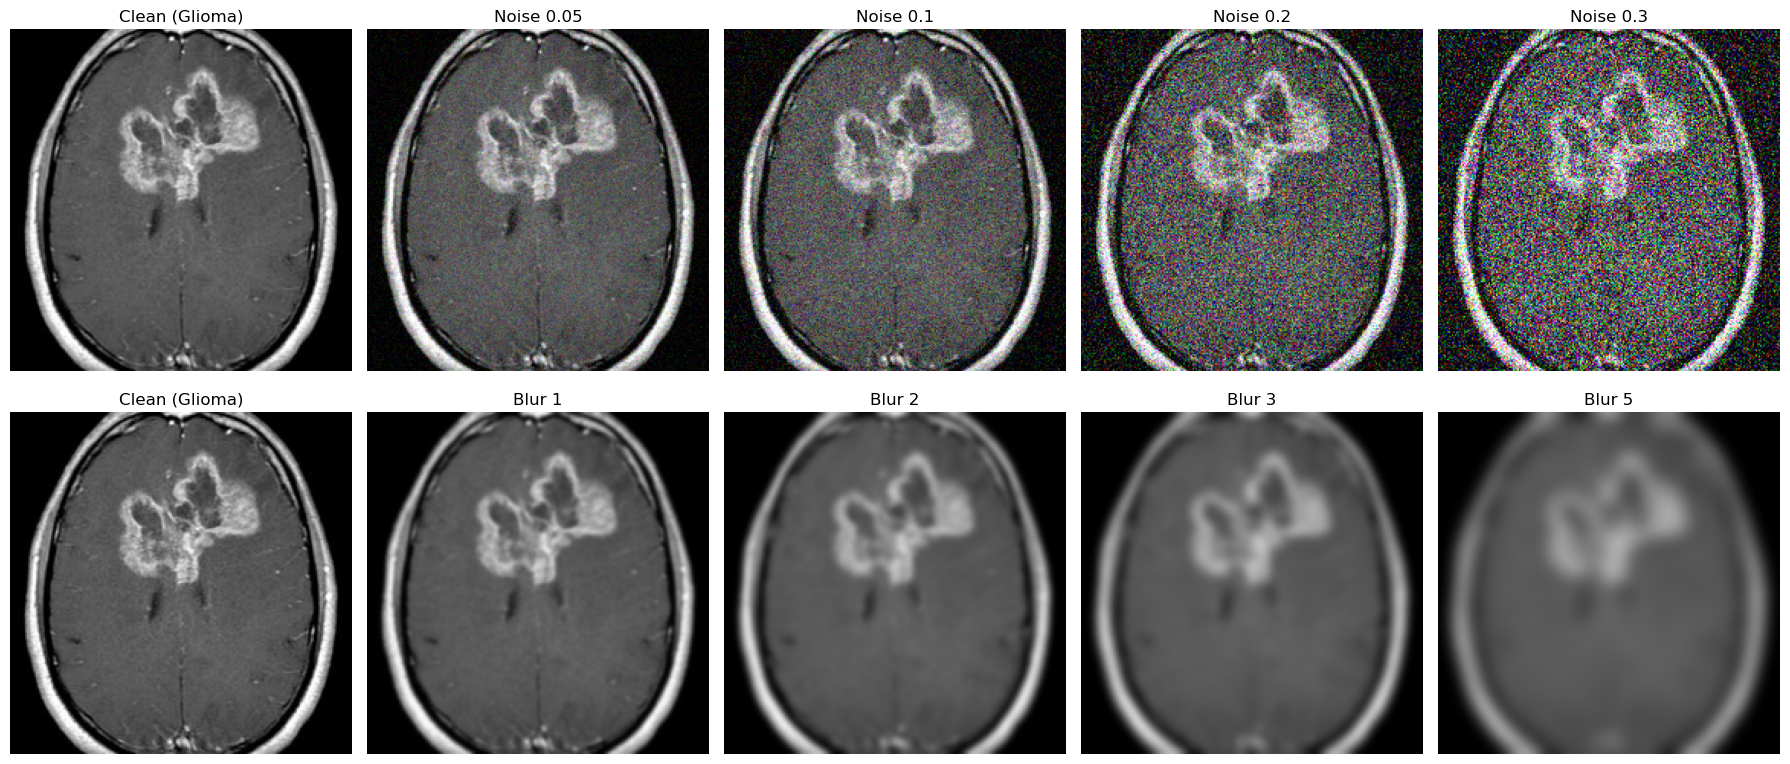

In [159]:
# take the first test image
example_class = test_integrity.iloc[0]["Class"]
example_path = Path(test_dir) / example_class / test_integrity.iloc[0]["File"]
example_image = Image.open(example_path).convert("RGB")
cropped_example = resize_options["center_crop"](example_image)

fig, axes = plt.subplots(2, 5, figsize=(18, 8))

# top row: clean + noise
axes[0][0].imshow(cropped_example)
axes[0][0].set_title("Clean (" + example_class + ")")
axes[0][0].axis("off")

torch.manual_seed(42)
col = 1
for sigma in noise_levels:
    image_tensor = transforms.ToTensor()(cropped_example)
    noisy_tensor = add_noise(image_tensor, sigma)
    axes[0][col].imshow(noisy_tensor.permute(1, 2, 0).numpy())
    axes[0][col].set_title("Noise " + str(sigma))
    axes[0][col].axis("off")
    col = col + 1

# bottom row: clean + blur
axes[1][0].imshow(cropped_example)
axes[1][0].set_title("Clean (" + example_class + ")")
axes[1][0].axis("off")

col = 1
for sigma in blur_levels:
    blurred = blur_image(cropped_example, sigma)
    axes[1][col].imshow(blurred)
    axes[1][col].set_title("Blur " + str(sigma))
    axes[1][col].axis("off")
    col = col + 1

plt.tight_layout()
plt.show()

### Run the Model on the Noisy and Blurred Test Images

Now the final model classifies the test images at every noise level and every blur level. This takes a while, so the predictions are saved in the folder. If they were already saved, the cell just loads them and does not run the model again. For the clean images I reuse the predictions from the clean test evaluation.

In [160]:
robust_file = os.path.join(saved_dir, "robustness_predictions.json")

if os.path.exists(robust_file):
    # already done before, just load it
    data = load_json("robustness_predictions.json")
    robust_preds = {}
    for name in data:
        robust_preds[name] = np.array(data[name])
    print("Loaded saved predictions:", list(robust_preds.keys()))

else:
    robust_preds = {}
    robust_preds["Clean"] = test_preds     # from the clean test evaluation

    # noise
    for sigma in noise_levels:
        torch.manual_seed(42)              # so the noise is the same every time
        this_dataset = BrainTumorDataset(test_integrity, transform=make_noise_transform(sigma), test_root=test_dir)
        this_loader = DataLoader(this_dataset, batch_size=32, shuffle=False, num_workers=0)
        this_loss, this_acc, this_preds, this_labels = evaluate(final_model, this_loader)

        robust_preds["Noise " + str(sigma)] = np.array(this_preds)
        print("Noise", sigma, "| accuracy:", round(this_acc, 4))

    # blur
    for sigma in blur_levels:
        this_dataset = BrainTumorDataset(test_integrity, transform=make_blur_transform(sigma), test_root=test_dir)
        this_loader = DataLoader(this_dataset, batch_size=32, shuffle=False, num_workers=0)
        this_loss, this_acc, this_preds, this_labels = evaluate(final_model, this_loader)

        robust_preds["Blur " + str(sigma)] = np.array(this_preds)
        print("Blur", sigma, "| accuracy:", round(this_acc, 4))

    # save so I do not have to run this again
    to_save = {}
    for name in robust_preds:
        to_save[name] = robust_preds[name].tolist()
    save_json(to_save, "robustness_predictions.json")
    print("Saved.")

Noise 0.05 | accuracy: 0.8581
Noise 0.1 | accuracy: 0.7506
Noise 0.2 | accuracy: 0.3325
Noise 0.3 | accuracy: 0.2675
Blur 1 | accuracy: 0.8969
Blur 2 | accuracy: 0.4494
Blur 3 | accuracy: 0.3588
Blur 5 | accuracy: 0.285
Saved.


### Overall Results

This table has one row for the clean images and one row for each noise and blur level. For each row it shows the overall accuracy with a 95% confidence interval (based on all 1,600 test images), the macro F1, how many points the accuracy dropped compared with the clean images, and the percentage of tumor images that were classified as No tumor (missed tumors).

The last column is the p-value of a McNemar test between that row and the clean predictions on the same images. If the p-value is small, the drop is probably not just chance.

In [161]:
from scipy.stats import binomtest

# make a list with the names of all the conditions
condition_names = ["Clean"]
for sigma in noise_levels:
    condition_names.append("Noise " + str(sigma))
for sigma in blur_levels:
    condition_names.append("Blur " + str(sigma))

clean_acc = 0
robust_acc = {}
result_rows = []

for name in condition_names:
    preds = robust_preds[name]

    # count how many it got right
    correct = 0
    for i in range(n_test):
        if preds[i] == test_labels[i]:
            correct = correct + 1

    acc = correct / n_test
    robust_acc[name] = acc
    if name == "Clean":
        clean_acc = acc

    low, high = wilson_ci(correct, n_test)
    prec, rec, f1, _ = precision_recall_fscore_support(
        test_labels, preds, average="macro", zero_division=0)

    # missed tumors = tumor image predicted as Notumor (class 3)
    tumor_total = 0
    missed = 0
    for i in range(n_test):
        if test_labels[i] != 3:
            tumor_total = tumor_total + 1
            if preds[i] == 3:
                missed = missed + 1

    # McNemar test compared with clean
    if name == "Clean":
        p_text = "-"
    else:
        clean_only = 0    # clean was right, this one is wrong
        level_only = 0    # clean was wrong, this one is right
        for i in range(n_test):
            clean_right = robust_preds["Clean"][i] == test_labels[i]
            level_right = preds[i] == test_labels[i]
            if clean_right and not level_right:
                clean_only = clean_only + 1
            if level_right and not clean_right:
                level_only = level_only + 1

        if clean_only + level_only > 0:
            p_value = binomtest(clean_only, clean_only + level_only, 0.5).pvalue
        else:
            p_value = 1.0
        p_text = round(p_value, 4)

    result_rows.append({
        "Condition": name,
        "Accuracy (%)": round(acc * 100, 2),
        "Acc CI low": round(low * 100, 2),
        "Acc CI high": round(high * 100, 2),
        "Macro F1": round(f1, 4),
        "Change vs clean (points)": round((acc - clean_acc) * 100, 2),
        "Missed tumors (%)": round(missed / tumor_total * 100, 2),
        "McNemar p vs clean": p_text
    })

robust_table = pd.DataFrame(result_rows)
print("The CI is for the OVERALL accuracy on", n_test, "test images")
robust_table

The CI is for the OVERALL accuracy on 1600 test images


,Condition,Accuracy (%),Acc CI low,Acc CI high,Macro F1,Change vs clean (points),Missed tumors (%),McNemar p vs clean
0,Clean,94.38,93.14,95.40,0.9427,0.00,3.25,-
1,Noise 0.05,85.81,84.02,87.44,0.8541,-8.56,5.58,0.0
2,Noise 0.1,75.06,72.88,77.12,0.7388,-19.31,20.75,0.0
3,Noise 0.2,33.25,30.98,35.60,0.2291,-61.12,78.75,0.0
4,Noise 0.3,26.75,24.64,28.97,0.1353,-67.62,96.92,0.0
5,Blur 1,89.69,88.10,91.08,0.8949,-4.69,8.42,0.0
6,Blur 2,44.94,42.52,47.38,0.3739,-49.44,64.42,0.0
7,Blur 3,35.88,33.56,38.26,0.2599,-58.50,80.25,0.0
8,Blur 5,28.50,26.34,30.76,0.1627,-65.88,93.58,0.0


### Recall for Each Class

The overall accuracy can hide a class that gets much worse than the others. So here I show the recall of each class for every condition. Each class has 400 test images, so these numbers change more easily than the overall accuracy.

In [162]:
recall_rows = []

for name in condition_names:
    preds = robust_preds[name]
    row = {"Condition": name}

    for class_name in classes:
        c = class_to_idx[class_name]

        n_class = 0
        correct_class = 0
        for i in range(n_test):
            if test_labels[i] == c:
                n_class = n_class + 1
                if preds[i] == c:
                    correct_class = correct_class + 1

        row[class_name + " recall (%)"] = round(correct_class / n_class * 100, 2)

    recall_rows.append(row)

recall_table = pd.DataFrame(recall_rows)
recall_table

,Condition,Glioma recall (%),Meningioma recall (%),Pituitary recall (%),Notumor recall (%)
0,Clean,82.25,96.25,99.00,100.00
1,Noise 0.05,69.75,74.25,100.00,99.25
2,Noise 0.1,56.25,50.25,93.75,100.00
3,Noise 0.2,28.00,5.25,0.25,99.50
4,Noise 0.3,3.25,3.75,0.00,100.00
5,Blur 1,71.00,90.50,97.25,100.00
6,Blur 2,19.75,58.75,1.25,100.00
7,Blur 3,4.00,39.50,0.00,100.00
8,Blur 5,0.00,14.00,0.00,100.00


### Robustness Curves

These two plots show how the test accuracy goes down when the noise (left) or the blur (right) gets stronger. The dashed line is the accuracy on the clean images. If a curve falls fast, the model is more sensitive to that kind of change.

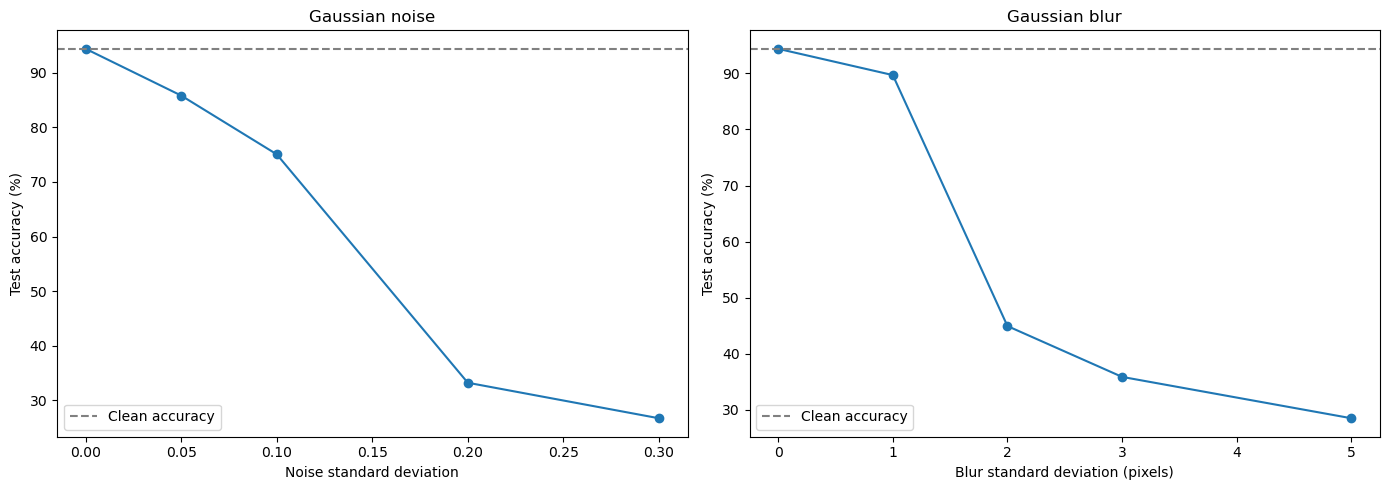

In [163]:
# accuracy values for the plots (the clean one is the first point)
noise_accs = [clean_acc * 100]
for sigma in noise_levels:
    noise_accs.append(robust_acc["Noise " + str(sigma)] * 100)

blur_accs = [clean_acc * 100]
for sigma in blur_levels:
    blur_accs.append(robust_acc["Blur " + str(sigma)] * 100)

noise_x = [0] + noise_levels
blur_x = [0] + blur_levels

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(noise_x, noise_accs, marker="o")
axes[0].axhline(clean_acc * 100, linestyle="--", color="gray", label="Clean accuracy")
axes[0].set_xlabel("Noise standard deviation")
axes[0].set_ylabel("Test accuracy (%)")
axes[0].set_title("Gaussian noise")
axes[0].legend()

axes[1].plot(blur_x, blur_accs, marker="o")
axes[1].axhline(clean_acc * 100, linestyle="--", color="gray", label="Clean accuracy")
axes[1].set_xlabel("Blur standard deviation (pixels)")
axes[1].set_ylabel("Test accuracy (%)")
axes[1].set_title("Gaussian blur")
axes[1].legend()

plt.tight_layout()
plt.show()

### Robustness Results: Overall

On the clean test images the model got 94.38% accuracy (95% CI 93.14 to 95.40) and 3.25% of the tumor images were missed (classified as No tumor). When I added noise or blur, the accuracy went down at every level, and all the drops are significant compared with the clean images (McNemar p < 0.0001 for every level). The confidence intervals are for the overall accuracy and are based on all 1,600 test images.

**Gaussian noise.** Accuracy went down to 85.81% at noise 0.05 (-8.56 points), 75.06% at 0.10 (-19.31 points), 33.25% at 0.20 (-61.12 points) and 26.75% at 0.30 (-67.62 points). The macro F1 went from 0.9427 on clean images to 0.8541, 0.7388, 0.2291 and 0.1353. The interval at noise 0.30 (24.64 to 28.97) includes 25%, which is the accuracy of random guessing on four balanced classes, so at that level the model is basically guessing.

**Gaussian blur.** Accuracy went down to 89.69% at blur 1 (-4.69 points), 44.94% at blur 2 (-49.44 points), 35.88% at blur 3 (-58.50 points) and 28.50% at blur 5 (-65.88 points). The macro F1 went down to 0.8949, 0.3739, 0.2599 and 0.1627.

**Missed tumors.** The share of tumor images classified as No tumor went from 3.25% on clean images to 5.58% and 20.75% at noise 0.05 and 0.10, and to 78.75% and 96.92% at noise 0.20 and 0.30. For blur it went to 8.42% at blur 1, 64.42% at blur 2, 80.25% at blur 3 and 93.58% at blur 5.

The drop is not slow and smooth. The accuracy falls a little at the mildest levels, and then it falls very fast between noise 0.10 and 0.20 and between blur 1 and blur 2.

### Robustness Results: Per Class

The recall table shows that the classes do not all get worse in the same way (each class has 400 test images).

Glioma was the most sensitive class. Its recall went from 82.25% on clean images to 69.75% at noise 0.05 and 71.00% at blur 1, and it was almost zero at noise 0.30 (3.25%) and blur 5 (0%). Meningioma was more stable against mild blur (90.50% at blur 1) but it dropped to 74.25% at noise 0.05 and to 5.25% at noise 0.20. Pituitary was the most stable class against mild noise (100% at noise 0.05 and 93.75% at 0.10), but at noise 0.20 its recall was 0.25%, and with blur it was 97.25% at blur 1 and only 1.25% at blur 2.

The No tumor class was different. Its recall stayed at 99.25% or higher in every condition, and it was 100% for noise 0.10, noise 0.30 and all blur levels. This does not mean the model is robust on these images. It means that when the images get bad, the model starts to label almost everything as No tumor, so the three tumor classes lose their recall and the No tumor class keeps its recall. This is why the missed tumor rate goes up so much.

### What the Robustness Results Mean

My proposal said that I expected the performance to go down when noise and blur are added, and the results agree with this. The model is also much more sensitive than I expected, because even the weakest distortions gave a significant drop and the strongest ones brought the model close to random guessing.

The most important result for a medical use is the way the model fails. The model does not say that it is unsure. It gives the answer No tumor, which is the most dangerous mistake. With only a mild blur (blur 1) the missed tumor rate went from 3.25% to 8.42%, and with noise 0.10 it was 20.75%.

A reason for this is that during training I only used flipping and a small rotation as augmentation, so the model never saw a noisy or blurred image. It is normal that a model fails on a kind of image that it never saw. I did not test a model trained with noise and blur, so I cannot say how much this would help.

Some things to note:

- The two distortions use different units (pixel intensity for noise, pixels for blur), so I cannot say that one is worse than the other.
- Gaussian noise added to the pixels is a simple test and is not the same as the noise of a real MRI scanner. The strongest levels (noise 0.20 and 0.30, blur 3 and 5) mostly destroy the images, so the most useful levels for judging the model are the mild ones (noise 0.05 and 0.10, blur 1 and 2).
- The noise is random. I used a fixed seed (42), so the results can be repeated, but I ran only one noise sample for each level.

### How Many Images Get the Label No Tumor?

In the recall table the No tumor class stays almost perfect while the other classes go to zero. To check my explanation, this table counts how many images the model labeled as No tumor in each condition, and how many of those really were No tumor images (the precision for this class). If my explanation is right, the number of No tumor labels should go up to almost all of the 1,600 images, and the precision should go down to about 25%.

In [164]:
notumor_rows = []

for name in condition_names:
    preds = robust_preds[name]

    notumor_predicted = 0    # images the model labeled Notumor
    notumor_correct = 0      # of those, how many really are Notumor
    for i in range(n_test):
        if preds[i] == 3:
            notumor_predicted = notumor_predicted + 1
            if test_labels[i] == 3:
                notumor_correct = notumor_correct + 1

    notumor_rows.append({
        "Condition": name,
        "Images labeled Notumor": notumor_predicted,
        "Share of all predictions (%)": round(notumor_predicted / n_test * 100, 2),
        "Notumor precision (%)": round(notumor_correct / notumor_predicted * 100, 2)
    })

notumor_table = pd.DataFrame(notumor_rows)
notumor_table

,Condition,Images labeled Notumor,Share of all predictions (%),Notumor precision (%)
0,Clean,439,27.44,91.12
1,Noise 0.05,464,29.00,85.56
2,Noise 0.1,649,40.56,61.63
3,Noise 0.2,1343,83.94,29.64
4,Noise 0.3,1563,97.69,25.59
5,Blur 1,501,31.31,79.84
6,Blur 2,1173,73.31,34.10
7,Blur 3,1363,85.19,29.35
8,Blur 5,1523,95.19,26.26


## Demo: Classify a New MRI Image

In this part I write a function that takes the path of an MRI image, runs it through the final model and tells me which of the four classes it is (Glioma, Meningioma, Pituitary tumor or No tumor). The image goes through exactly the same steps as the test images: it is converted to RGB, center cropped to 224 x 224 and normalized with the ImageNet values.

The function also shows the probability the model gives to each class, so I can see how sure it is.

In [165]:
from PIL import UnidentifiedImageError

# names to print for each class
nice_names = {
    "Glioma": "Glioma",
    "Meningioma": "Meningioma",
    "Pituitary": "Pituitary tumor",
    "Notumor": "No tumor"
}

def classify_image(image_path, show=True):
    # remove the quotes and spaces that Windows adds when I copy a path
    image_path = image_path.strip().strip('"').strip("'")

    # check that the file exists
    if not os.path.exists(image_path):
        print("File not found:", image_path)
        return None

    # try to open the image
    try:
        image = Image.open(image_path).convert("RGB")
    except UnidentifiedImageError:
        print("This file is not an image that I can read.")
        return None
    except Exception as error:
        print("Could not open the file:", error)
        return None

    # same preprocessing as the test images
    tensor = final_eval_transform(image)
    tensor = tensor.unsqueeze(0).to(device)     # add the batch dimension

    # run the model
    final_model.eval()
    with torch.no_grad():
        outputs = final_model(tensor)
        probabilities = torch.softmax(outputs, dim=1)[0]

    probabilities = probabilities.cpu().numpy()
    best_number = int(probabilities.argmax())
    best_class = classes[best_number]
    best_probability = float(probabilities[best_number])

    # print the result
    print("Image:", image_path)
    print("Image size:", image.size)
    print()
    print("Prediction:", nice_names[best_class])
    print("Probability:", round(best_probability * 100, 2), "%")
    print()
    print("Probability of each class:")
    for i in range(len(classes)):
        print("  ", nice_names[classes[i]], ":", round(float(probabilities[i]) * 100, 2), "%")

    if best_probability < 0.70:
        print()
        print("Warning: the model is not sure about this image (below 70%).")

    # show the image and the probabilities
    if show:
        fig, axes = plt.subplots(1, 2, figsize=(12, 5))

        axes[0].imshow(image)
        axes[0].set_title("Prediction: " + nice_names[best_class])
        axes[0].axis("off")

        names_for_plot = []
        for class_name in classes:
            names_for_plot.append(nice_names[class_name])

        axes[1].barh(names_for_plot, probabilities * 100)
        axes[1].set_xlim(0, 100)
        axes[1].set_xlabel("Probability (%)")
        axes[1].set_title("Probability of each class")

        plt.tight_layout()
        plt.show()

    return {"prediction": best_class, "probability": best_probability,
            "all_probabilities": probabilities}

print("Prediction function ready.")

Prediction function ready.


### Quick Check With Test Images

Before I use the function on new images, I check that it works. I take the first test image of each class, run the function on it, and compare the answer with the true class. The result should match the model's behavior on the test set, where Glioma was the weakest class.

In [167]:
for class_name in classes:
    rows = test_integrity[test_integrity["Class"] == class_name]
    file_name = rows.iloc[0]["File"]
    path = os.path.join(str(test_dir), class_name, file_name)

    result = classify_image(path, show=False)

    print("Actual Class:", nice_names[class_name])
    print("Predicted Class:", nice_names[result["prediction"]])
    print()

Image: C:\Users\BLOB\Desktop\AdvancedCompVision\BrainTumor_Classification\Datasets\Testing\Glioma\Te-gl_1.jpg
Image size: (354, 442)

Prediction: No tumor
Probability: 94.27 %

Probability of each class:
   Glioma : 0.72 %
   Meningioma : 2.74 %
   Pituitary tumor : 2.27 %
   No tumor : 94.27 %
Actual Class: Glioma
Predicted Class: No tumor

Image: C:\Users\BLOB\Desktop\AdvancedCompVision\BrainTumor_Classification\Datasets\Testing\Meningioma\Te-aug-me_1.jpg
Image size: (512, 512)

Prediction: Meningioma
Probability: 100.0 %

Probability of each class:
   Glioma : 0.0 %
   Meningioma : 100.0 %
   Pituitary tumor : 0.0 %
   No tumor : 0.0 %
Actual Class: Meningioma
Predicted Class: Meningioma

Image: C:\Users\BLOB\Desktop\AdvancedCompVision\BrainTumor_Classification\Datasets\Testing\Pituitary\Te-pi_1.jpg
Image size: (512, 512)

Prediction: Pituitary tumor
Probability: 99.9 %

Probability of each class:
   Glioma : 0.0 %
   Meningioma : 0.1 %
   Pituitary tumor : 99.9 %
   No tumor : 0.0 

### Classify an Image

This cell requests for the path of an MRI image. The model then classifies it and shows the image with the probability of each class. 

Image: C:\Users\BLOB\Desktop\AdvancedCompVision\imagess.jpeg
Image size: (403, 496)

Prediction: Meningioma
Probability: 69.06 %

Probability of each class:
   Glioma : 0.0 %
   Meningioma : 69.06 %
   Pituitary tumor : 16.01 %
   No tumor : 14.93 %



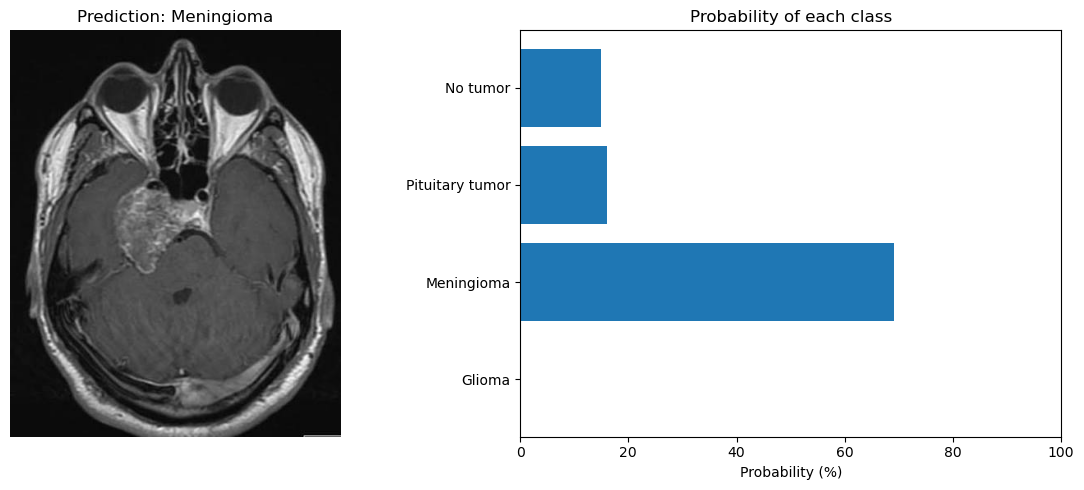

In [174]:
path = r"C:\Users\BLOB\Desktop\AdvancedCompVision\imagess.jpeg"
result = classify_image(path)